# **Geopatial ML Inference: DIP Notebook**

# **Name:** Abhigyan Pandey
# **Roll No.:** 23CS3070
# **Branch:** CSE

# **Name:** Pankaj Kumar
# Roll No.: 23CS3073
# **Branch:** CSE

#### Do enhancement, spatial-filter-derived features and spectral indices change the separability, stability and spatial organisation of unsupervised image-pattern groups?

**Offline-capable Digital Image Processing pipeline · Sentinel-2 (B02/B03/B04/B08) BHU–Ganga River corridor, Varanasi and Bengaluru region**

### Central research question
How do image enhancement and feature representation (raw bands → + spectral indices → + DIP spatial features) influence the **separability, run-to-run stability and spatial organisation** of patterns found by an identical unsupervised clustering workflow?

| RQ | Question | Evidence produced by this notebook |
|---|---|---|
| RQ1 | How do gamma, histogram equalisation and CLAHE change contrast and information content? | entropy, RMS contrast, dynamic range, edge density (§4) |
| RQ2 | What local structure do Gaussian / Sobel / Laplacian / Canny expose? | edge maps, edge density (§5) |
| RQ3 | Does adding NDVI/NDWI, then DIP spatial features (gradient, local texture), change cluster separability? | own-space **and common-reference-space** silhouette, Davies–Bouldin, Calinski–Harabasz (§9–10) |
| RQ4 | Are the groups stable and spatially coherent? | seed-stability ARI, connected components, patch sizes, fragmentation, majority-filter effect (§11–13) |
| RQ5 | Do cluster boundaries coincide with DIP-detected edges? | Canny-boundary alignment enrichment (§13) |

### What is (and is not) novel here
No new clustering algorithm is claimed. The contribution is a **controlled, reproducible integration** of classical DIP and lightweight ML:
1. a three-level feature ablation in which **DIP-derived spatial features** (Sobel gradient magnitude, local standard deviation) are a first-class feature group;
2. a **common reference space** evaluation, so feature sets with different dimensionality can be compared fairly (plain silhouette scores in different spaces are *not* comparable);
3. **edge–boundary coherence**: how strongly cluster boundaries are enriched in Canny edges relative to chance;
4. **spatial fragmentation** metrics and a majority-filter comparison (is spatial-feature augmentation doing what post-hoc smoothing does?);
5. **seed-stability** (adjusted Rand index) as a reliability measure;
6. one **serialised bundle** (scaler + model + feature schema + preprocessing) with reload verification and offline inference.

### Scientific honesty
K-Means groups pixels by feature similarity. **Cluster IDs are arbitrary and are not verified land-cover classes.** Silhouette / DB / CH are internal geometric measures, **not accuracy**. The water-consistency check compares clusters with an NDWI mask derived from the *same bands* — it is a consistency check, not validation. No independent reference labels are used, so **no accuracy is claimed**.

### Pipeline
```
input(s) → read + metadata → validity mask (NaN / all-zero) → [optional resize] → reflectance check
   → display composites + stats → DIP enhancement (γ, HE, CLAHE) → DIP filtering (Gaussian, Sobel, LoG, Canny)
   → feature groups: A raw | B raw+NDVI+NDWI | C raw+NDVI+NDWI+gradient+texture
   → StandardScaler + MiniBatch K-Means (sample fit, batch predict) for A, B, C
   → separability (own + common space) · K-sweep · seed stability
   → spatial analysis (components, patches, fragmentation, majority filter, Canny alignment, cross-set agreement)
   → cluster spectral summaries + projected-CRS areas → GeoTIFF / CSV / PNG / joblib bundle / JSON → offline inference check
```

### Pseudocode
```
read bands; mask = finite AND NOT all-zero; reflectance = DN/10000 if needed
for each feature set S in {A, B, C}:
    X = stack(features of S)[mask]
    fit StandardScaler + MiniBatchKMeans(K) on random sample of X
    labels = predict(all X in batches)
    evaluate: silhouette/DB/CH in own space and in common (A) space on a FIXED pixel subsample
    stability = mean pairwise ARI over R re-fits with different seeds
    spatial = components, mean/largest patch, fragmentation, boundary density, Canny enrichment
    labels_smooth = majority_filter(labels);  compare fragmentation
export labels (GeoTIFF), tables, figures, model bundle; verify reload and offline inference
```

> **Environment note.** Colab is cloud-hosted and is *not* air-gapped. Install dependencies once, then run the saved bundle locally with the network disconnected to claim offline operation.

## Environment, configuration and reproducibility

In [ ]:
%pip -q install numpy pandas matplotlib scikit-learn opencv-python-headless rasterio scipy pillow joblib pyproj

In [ ]:
import os, sys, re, json, warnings, itertools, datetime, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2, rasterio, joblib, sklearn
from rasterio.transform import Affine
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from PIL import Image
from pyproj import CRS
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})

# ------------------------------ CONFIGURATION ------------------------------
CFG = dict(
    seed=42,
    n_clusters=4,                 # K used for the main comparison (justified by the K-sweep in section 10)
    k_sweep=(2, 3, 4, 5, 6, 7, 8),
    max_dimension=2000,           # downsample only if larger (None = never). Recorded in metadata.
    max_train=50000,              # pixels used to fit scaler + K-Means
    eval_pixels=5000,             # FIXED pixel subsample for every separability metric
    stability_runs=5,             # re-fits with different seeds for the stability (ARI) test
    stability_pixels=20000,
    gamma=0.8, clahe_clip=2.0, clahe_tile=8,
    gauss_sigma=1.0,              # Gaussian smoothing before Sobel / Canny / spatial features
    texture_window=5,             # local-std window (pixels)
    majority_window=3,            # majority-filter window
)
SPECTRAL = "auto"   # "auto": spectral indices only if the 4 Sentinel-2 band files (B02,B03,B04,B08) or band descriptions identify the bands
                    # "on"  : force (single multiband file) using BAND_MAP below   |  "off": never compute indices
BAND_MAP = {"blue": 1, "green": 2, "red": 3, "nir": 4}   # 1-based; only used with SPECTRAL="on"
INPUT_PATHS = None  # e.g. ["data/B02.tiff","data/B03.tiff","data/B04.tiff","data/B08.tiff"]; None -> Colab upload / ./input folder
EPS = 1e-8
SEED = CFG["seed"]; K = CFG["n_clusters"]
rng = np.random.default_rng(SEED)

OUT = Path("GeoVision_DIP_Output")
FIG, TAB, RAS, MOD = OUT/"figures", OUT/"tables", OUT/"rasters", OUT/"models"
for d in (FIG, TAB, RAS, MOD): d.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.savefig(FIG/name, bbox_inches="tight"); print("saved", FIG/name)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| OpenCV", cv2.__version__,
      "| rasterio", rasterio.__version__, "| scikit-learn", sklearn.__version__)

Python 3.13.18 | numpy 2.4.6 | OpenCV 5.0.0 | rasterio 1.5.2 | scikit-learn 1.6.1


# **VARANASI**

## Input
**Varanasi:** select the four Sentinel-2 band GeoTIFFs (B02, B03, B04, B08). Band identity is read from the filenames (e.g. `..._B02_(Raw).tiff`), so spectral indices are enabled automatically and safely.
**Any other image:** upload one RGB/grayscale/TIFF image. Spectral indices are then skipped unless you set `SPECTRAL="on"` and verify `BAND_MAP`.

In [47]:
from google.colab import files
import rasterio
import numpy as np
from pathlib import Path

uploaded = files.upload()

# Identify the four uploaded bands
band_files = {}
for name in uploaded:
    lower = name.lower()
    for band in ["b02", "b03", "b04", "b08"]:
        if band in lower and lower.endswith((".tif", ".tiff")):
            band_files[band] = name

required = ["b02", "b03", "b04", "b08"]

if not all(b in band_files for b in required):
    raise ValueError(f"Missing bands. Found: {list(band_files)}")

# Stack bands in the correct order
band_order = ["b02", "b03", "b04", "b08"]
arrays = []

with rasterio.open(band_files["b02"]) as src:
    profile = src.profile.copy()
    reference_shape = (src.height, src.width)
    reference_transform = src.transform
    reference_crs = src.crs

for band in band_order:
    with rasterio.open(band_files[band]) as src:
        assert (src.height, src.width) == reference_shape
        assert src.transform == reference_transform
        assert src.crs == reference_crs
        arrays.append(src.read(1).astype(np.float32))

# Create four-band GeoTIFF
profile.update(
    driver="GTiff",
    count=4,
    dtype="float32",
    compress="lzw"
)

RASTER_PATH = str(INPUT_DIR / "Sentinel2_BHU_4band.tif")

with rasterio.open(RASTER_PATH, "w", **profile) as dst:
    for i, arr in enumerate(arrays, start=1):
        dst.write(arr, i)
        dst.set_band_description(i, band_order[i-1].upper())

print("Four-band raster created:", RASTER_PATH)
print("Band order: B02, B03, B04, B08")

Saving 2021-12-26-00_00_2021-12-26-23_59_Sentinel-2_L2A_B02_(Raw).tiff to 2021-12-26-00_00_2021-12-26-23_59_Sentinel-2_L2A_B02_(Raw) (2).tiff
Saving 2021-12-26-00_00_2021-12-26-23_59_Sentinel-2_L2A_B03_(Raw).tiff to 2021-12-26-00_00_2021-12-26-23_59_Sentinel-2_L2A_B03_(Raw) (2).tiff
Saving 2021-12-26-00_00_2021-12-26-23_59_Sentinel-2_L2A_B04_(Raw).tiff to 2021-12-26-00_00_2021-12-26-23_59_Sentinel-2_L2A_B04_(Raw) (2).tiff
Saving 2021-12-26-00_00_2021-12-26-23_59_Sentinel-2_L2A_B08_(Raw).tiff to 2021-12-26-00_00_2021-12-26-23_59_Sentinel-2_L2A_B08_(Raw) (2).tiff
Four-band raster created: /content/Sentinel2_BHU_4band.tif
Band order: B02, B03, B04, B08


In [48]:
IMG_EXT = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}
BAND_KEYS = ["b02", "b03", "b04", "b08"]

def find_inputs():
    if INPUT_PATHS: return [Path(p) for p in INPUT_PATHS]
    env = os.environ.get("GEOVISION_INPUT")            # optional, for local/headless runs
    if env: return [Path(p) for p in env.split(os.pathsep)]
    try:
        from google.colab import files
        up = files.upload()
        return [Path(k) for k in up]
    except ImportError:
        return sorted(p for p in Path("input").glob("*") if p.suffix.lower() in IMG_EXT)

paths = find_inputs()
if not paths: raise FileNotFoundError("No input found. Upload files in Colab or set INPUT_PATHS.")
for p in paths:
    if not p.exists(): raise FileNotFoundError(p)
print("Input files:")
for p in paths: print("  ", p.name)

Saving Sentinel2_BHU_4band.tif to Sentinel2_BHU_4band (1).tif
Input files:
   Sentinel2_BHU_4band (1).tif


## Reading, validity mask and reflectance check (`prepare`)
Improvements over the earlier notebook: (i) a pixel is **invalid** if any band is non-finite **or all bands are exactly 0** (zero-padding of Sentinel Hub exports was previously counted as valid and distorted the percentiles); (ii) resizing uses area averaging and keeps only pixels whose whole footprint was valid; (iii) one function is reused for training and offline inference, so preprocessing is identical.

In [49]:
def band_key(path):
    n = path.name.lower()
    for k in BAND_KEYS:
        if re.search(rf"(?<![a-z0-9]){k}(?![a-z0-9])", n): return k
    return None

def load_input(paths):
    info = dict(source=[p.name for p in paths], geo=False, crs=None, transform=None,
                spectral_verified=False, band_map=None, descriptions=None)
    keys = {band_key(p): p for p in paths if band_key(p)}
    if all(k in keys for k in BAND_KEYS):                       # four separate Sentinel-2 files
        with rasterio.open(keys["b02"]) as ref:
            shp, tf, crs = (ref.height, ref.width), ref.transform, ref.crs
        arrs = []
        for k in BAND_KEYS:
            with rasterio.open(keys[k]) as s:
                if (s.height, s.width) != shp or s.transform != tf or s.crs != crs:
                    raise ValueError(f"{k.upper()} is not aligned with B02 (size/transform/CRS). Align bands first.")
                arrs.append(s.read(1, masked=True).astype(np.float32).filled(np.nan))
        info.update(geo=crs is not None, crs=crs, transform=tf, spectral_verified=True,
                    band_map={"blue": 1, "green": 2, "red": 3, "nir": 4},
                    descriptions=[k.upper() for k in BAND_KEYS])
        return np.stack(arrs).astype(np.float32), info
    p = paths[0]
    if len(paths) > 1: print("Note: using only the first file:", p.name)
    if p.suffix.lower() in (".tif", ".tiff"):
        try:
            with rasterio.open(p) as s:
                arr = s.read(masked=True).astype(np.float32).filled(np.nan)
                desc = [str(d).upper() if d else None for d in s.descriptions]
                info.update(geo=s.crs is not None, crs=s.crs, transform=s.transform, descriptions=desc)
                if desc[:4] == ["B02", "B03", "B04", "B08"]:
                    info.update(spectral_verified=True, band_map={"blue": 1, "green": 2, "red": 3, "nir": 4})
            return arr, info
        except Exception as e:
            print("rasterio could not read this TIFF, trying Pillow:", e)
    im = Image.open(p)
    if im.mode in ("P", "RGBA", "CMYK", "LA"): im = im.convert("RGB")
    a = np.array(im)
    a = a[None] if a.ndim == 2 else np.moveaxis(a[..., :3], -1, 0)
    return a.astype(np.float32), info

def prepare(paths, spectral_mode=SPECTRAL, band_map=BAND_MAP, cfg=CFG, divisor=None, verbose=True):
    raster, info = load_input(paths)
    B, H0, W0 = raster.shape
    valid0 = np.all(np.isfinite(raster), axis=0)
    n_nonfinite = int((~valid0).sum())
    n_allzero = 0
    if info["geo"]:
        allzero = np.all(raster == 0, axis=0) & valid0
        n_allzero = int(allzero.sum()); valid0 &= ~allzero
    H, W, md_ = H0, W0, cfg["max_dimension"]
    if md_ and max(H0, W0) > md_:
        s = md_ / max(H0, W0); W, H = max(1, round(W0*s)), max(1, round(H0*s))
        filled = np.nan_to_num(raster, nan=0.0)
        raster = np.stack([cv2.resize(b, (W, H), interpolation=cv2.INTER_AREA) for b in filled])
        valid = cv2.resize(valid0.astype(np.float32), (W, H), interpolation=cv2.INTER_AREA) > 0.999
    else:
        valid = valid0
    raster = np.where(valid[None], np.nan_to_num(raster, nan=0.0), 0).astype(np.float32)
    if not valid.any(): raise ValueError("No valid pixels.")
    if spectral_mode == "off": spectral = False
    elif spectral_mode == "on": spectral = B >= 4
    else: spectral = bool(info["spectral_verified"])
    bm = info["band_map"] or band_map
    bidx = {k: v-1 for k, v in bm.items()}
    if spectral:
        if max(bidx.values()) >= B or min(bidx.values()) < 0: raise ValueError("BAND_MAP invalid for this raster.")
        if divisor is None:
            divisor = 10000.0 if np.percentile(raster[:, valid], 99) > 2 else 1.0
        raster = raster / divisor
    else:
        divisor = 1.0
    work_tf = (info["transform"] * Affine.scale(W0/W, H0/H)) if info["geo"] else None
    st = dict(raster=raster, valid=valid, spectral=spectral, bidx=bidx, divisor=divisor, info=info,
              B=B, H=H, W=W, H0=H0, W0=W0, work_transform=work_tf, crs=info["crs"],
              n_nonfinite=n_nonfinite, n_allzero=n_allzero, band_map=bm)
    if verbose:
        print(f"Native shape (bands,rows,cols): ({B},{H0},{W0}) | working: ({B},{H},{W})")
        print(f"Invalid pixels: non-finite={n_nonfinite:,}, all-zero={n_allzero:,} | valid={int(valid.sum()):,} ({100*valid.mean():.2f}%)")
        print(f"CRS: {info['crs']} | spectral mode: {spectral} | reflectance divisor: {divisor:g}")
        if info["geo"]: print("Native pixel size (m):", abs(info['transform'].a), abs(info['transform'].e))
    return st

S = prepare(paths)
raster, valid, spectral, bidx = S["raster"], S["valid"], S["spectral"], S["bidx"]
B, H, W, H0, W0 = S["B"], S["H"], S["W"], S["H0"], S["W0"]
info = S["info"]

Native shape (bands,rows,cols): (4,416,386) | working: (4,416,386)
Invalid pixels: non-finite=0, all-zero=3,920 | valid=156,656 (97.56%)
CRS: EPSG:32644 | spectral mode: True | reflectance divisor: 1
Native pixel size (m): 9.193213546632336 9.115969413460475


## Composites, channel statistics and histograms
Percentile stretching is for **display only**; analytical features use the original reflectance values.

saved GeoVision_DIP_Output/figures/composites.png


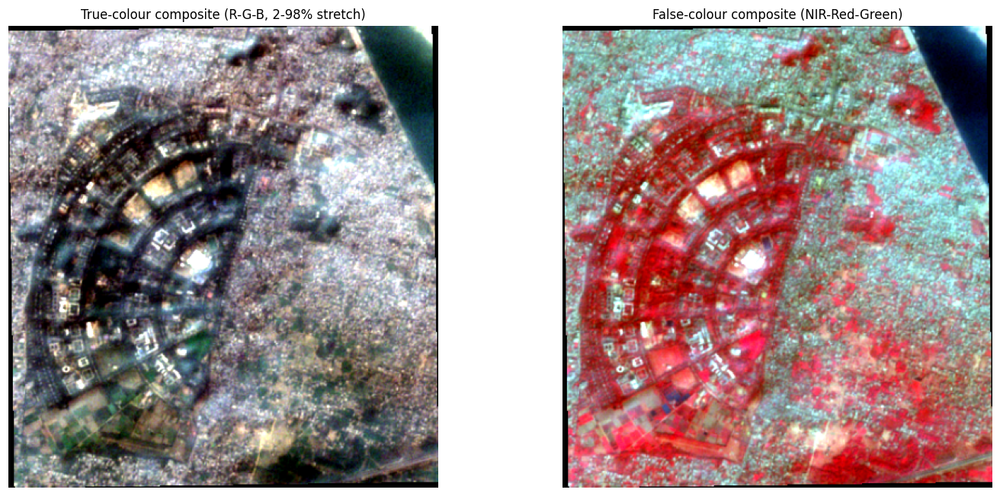

,channel,min,max,mean,std,p2,p98
0,Blue,0.1204,0.2612,0.1581,0.0122,0.1355,0.1829
1,Green,0.1283,0.2926,0.1662,0.0133,0.1419,0.1933
2,Red,0.1177,0.3317,0.1642,0.0192,0.1296,0.2023
3,NIR,0.0954,0.4177,0.2217,0.0306,0.1116,0.2828


saved GeoVision_DIP_Output/figures/channel_histograms.png


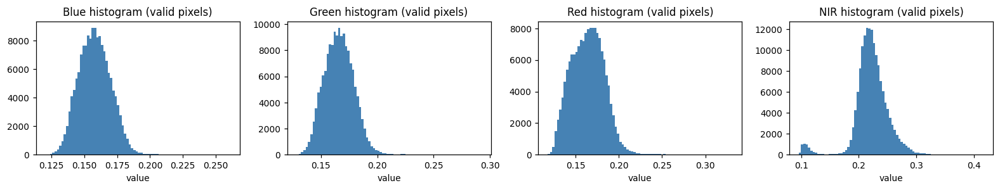

In [50]:
def stretch(a, mask, lo=2, hi=98):
    v = a[mask]; out = np.zeros(a.shape, np.float32)
    if v.size:
        p, q = np.percentile(v, [lo, hi])
        if q > p: out = np.clip((a - p)/(q - p), 0, 1).astype(np.float32)
    out[~mask] = 0
    return out

def display_rgb(st):
    r, v = st["raster"], st["valid"]
    if st["spectral"]:   idx = [st["bidx"]["red"], st["bidx"]["green"], st["bidx"]["blue"]]
    elif st["B"] >= 3:   idx = [0, 1, 2]
    else:                idx = [0, 0, 0]
    return np.stack([stretch(r[i], v) for i in idx], -1), idx

rgb, rgb_idx = display_rgb(S)
fig, ax = plt.subplots(1, 2 if (spectral) else 1, figsize=(14 if spectral else 7, 6), squeeze=False); ax = ax[0]
ax[0].imshow(rgb); ax[0].set_title("True-colour composite (R-G-B, 2-98% stretch)" if spectral else "Input image (display-stretched)"); ax[0].axis("off")
if spectral:
    fc = np.stack([stretch(raster[bidx["nir"]], valid), stretch(raster[bidx["red"]], valid), stretch(raster[bidx["green"]], valid)], -1)
    ax[1].imshow(fc); ax[1].set_title("False-colour composite (NIR-Red-Green)"); ax[1].axis("off")
plt.tight_layout(); savefig("composites.png"); plt.show()

names_ch = ["Blue", "Green", "Red", "NIR"] if spectral else [f"Ch{i+1}" for i in range(B)]
chan_order = [bidx[k] for k in ["blue", "green", "red", "nir"]] if spectral else list(range(B))
rows = []
for nm, i in zip(names_ch, chan_order):
    v = raster[i][valid]
    rows.append(dict(channel=nm, min=v.min(), max=v.max(), mean=v.mean(), std=v.std(),
                     p2=np.percentile(v, 2), p98=np.percentile(v, 98)))
band_stats = pd.DataFrame(rows).round(4); display(band_stats)
band_stats.to_csv(TAB/"image_channel_statistics.csv", index=False)
fig, axs = plt.subplots(1, len(chan_order), figsize=(3.6*len(chan_order), 2.8), squeeze=False)
for a, nm, i in zip(axs[0], names_ch, chan_order):
    a.hist(raster[i][valid], bins=80, color="steelblue"); a.set_title(f"{nm} histogram (valid pixels)"); a.set_xlabel("value")
plt.tight_layout(); savefig("channel_histograms.png"); plt.show()

## DIP — intensity enhancement (RQ1)
Gamma correction, **mask-aware** global histogram equalisation, and CLAHE are applied to the display luminance. They are compared quantitatively by Shannon entropy, RMS contrast (std) and dynamic range (p98−p2). Enhancement is a display/interpretation step: it is **not** substituted for calibrated reflectance in the feature matrix.

,method,entropy_bits,rms_contrast_std,dynamic_range_p98_p2,mean
0,Original,7.8587,0.2418,0.9581,0.4710
1,Gamma,7.8203,0.2324,0.9378,0.5337
2,Hist. equalisation,7.6714,0.2917,0.9694,0.4970
3,CLAHE,7.9412,0.2646,0.9569,0.4997


saved GeoVision_DIP_Output/figures/enhancement_comparison.png


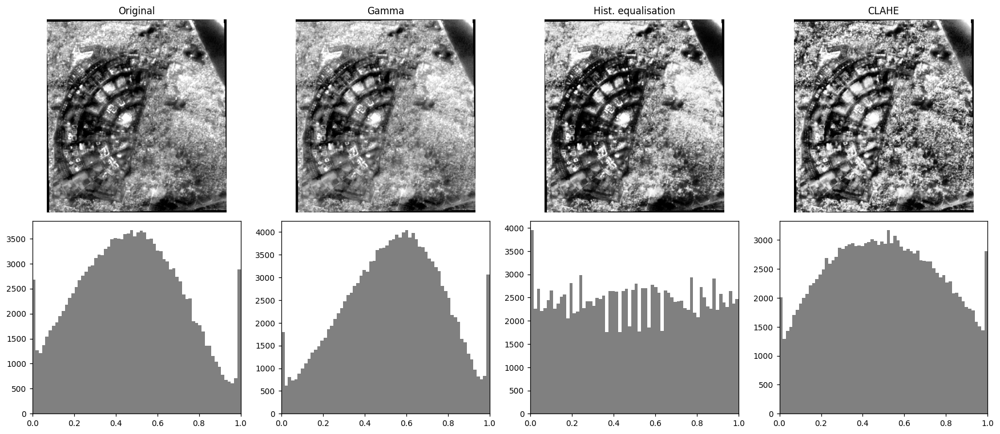

In [51]:
gray = (0.299*rgb[..., 0] + 0.587*rgb[..., 1] + 0.114*rgb[..., 2]).astype(np.float32)
valid_in = ndi.binary_erosion(valid, iterations=2)          # excludes edge artefacts at the data border

def gamma_correct(x, g): return np.clip(x, 0, 1)**g
def hist_equalize(x, mask):
    u = np.uint8(np.clip(x, 0, 1)*255); h = np.bincount(u[mask], minlength=256).astype(float)
    cdf = np.cumsum(h); cdf = (cdf - cdf[cdf > 0].min())/max(cdf[-1] - cdf[cdf > 0].min(), 1)
    out = np.clip(cdf, 0, 1)[u].astype(np.float32); out[~mask] = 0; return out
def clahe(x, mask, clip, tile):
    u = np.uint8(np.clip(x, 0, 1)*255); u = u.copy(); u[~mask] = np.uint8(np.median(u[mask]))
    out = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(u).astype(np.float32)/255
    out[~mask] = 0; return out
def entropy(x, mask):
    h = np.bincount(np.uint8(np.clip(x, 0, 1)*255)[mask], minlength=256).astype(float); p = h[h > 0]/h.sum()
    return float(-(p*np.log2(p)).sum())

enh = {"Original": gray, "Gamma": gamma_correct(gray, CFG["gamma"]),
       "Hist. equalisation": hist_equalize(gray, valid),
       "CLAHE": clahe(gray, valid, CFG["clahe_clip"], CFG["clahe_tile"])}
enh_rows = []
for k, v in enh.items():
    x = v[valid]
    enh_rows.append({"method": k, "entropy_bits": entropy(v, valid), "rms_contrast_std": float(x.std()),
                     "dynamic_range_p98_p2": float(np.percentile(x, 98) - np.percentile(x, 2)), "mean": float(x.mean())})
enh_df = pd.DataFrame(enh_rows).round(4); display(enh_df); enh_df.to_csv(TAB/"enhancement_metrics.csv", index=False)
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for j, (k, v) in enumerate(enh.items()):
    axs[0, j].imshow(v, cmap="gray", vmin=0, vmax=1); axs[0, j].set_title(k); axs[0, j].axis("off")
    axs[1, j].hist(v[valid], bins=64, color="gray"); axs[1, j].set_xlim(0, 1)
plt.tight_layout(); savefig("enhancement_comparison.png"); plt.show()

## DIP — spatial filtering and edge detection (RQ2)
Gaussian smoothing suppresses noise; Sobel estimates the gradient (magnitude and direction); the Laplacian of Gaussian responds to rapid intensity change; Canny adds non-maximum suppression and hysteresis. Canny thresholds are chosen automatically from Otsu's threshold (high = Otsu, low = 0.5·high) so the pipeline is image-agnostic. The Canny map `edges` is reused in §13 to test cluster-boundary alignment.

saved GeoVision_DIP_Output/figures/spatial_filters.png


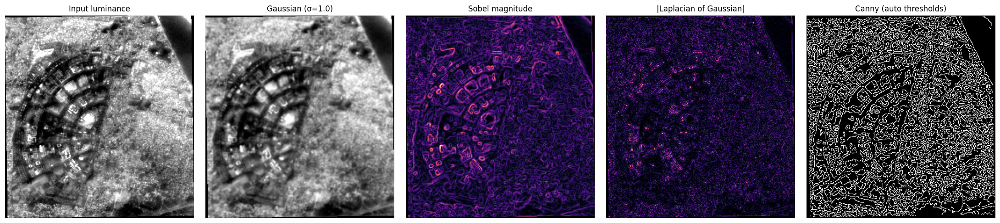

,input,canny_edge_density_%
0,original luminance,23.835
1,CLAHE-enhanced luminance,26.286


In [52]:
def auto_canny(u8, mask):
    hi, _ = cv2.threshold(u8[mask].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    hi = float(max(hi, 20)); return cv2.Canny(u8, 0.5*hi, hi) > 0

def filters(img, mask, sigma):
    g = cv2.GaussianBlur(np.ascontiguousarray(img, np.float32), (0, 0), sigma)
    sx, sy = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    mag, ang = cv2.magnitude(sx, sy), np.degrees(np.arctan2(sy, sx))
    log = cv2.Laplacian(g, cv2.CV_32F, ksize=3)
    e = auto_canny(np.uint8(np.clip(g, 0, 1)*255), mask) & valid_in
    return g, mag, ang, log, e

gray_fill = gray.copy(); gray_fill[~valid] = np.median(gray[valid])      # avoid artificial border edges
g, sob, ang, lap, edges = filters(gray_fill, valid, CFG["gauss_sigma"])
n01 = lambda x: np.abs(x)/max(np.abs(x[valid_in]).max(), 1e-9)
fig, axs = plt.subplots(1, 5, figsize=(20, 4.3))
for a, (im, t, cm) in zip(axs, [(gray, "Input luminance", "gray"), (g, f"Gaussian (σ={CFG['gauss_sigma']})", "gray"),
                                (n01(sob), "Sobel magnitude", "magma"), (n01(lap), "|Laplacian of Gaussian|", "magma"),
                                (edges, "Canny (auto thresholds)", "gray")]):
    a.imshow(np.where(valid, im, 0), cmap=cm); a.set_title(t); a.axis("off")
plt.tight_layout(); savefig("spatial_filters.png"); plt.show()

edges_clahe = auto_canny(np.uint8(np.clip(cv2.GaussianBlur(enh["CLAHE"], (0, 0), CFG["gauss_sigma"]), 0, 1)*255), valid) & valid_in
edge_df = pd.DataFrame([{"input": "original luminance", "canny_edge_density_%": 100*edges[valid_in].mean()},
                        {"input": "CLAHE-enhanced luminance", "canny_edge_density_%": 100*edges_clahe[valid_in].mean()}]).round(3)
display(edge_df); edge_df.to_csv(TAB/"edge_density_original_vs_clahe.csv", index=False)

## Spectral indices (spectral mode only)
NDVI = (NIR − Red)/(NIR + Red); McFeeters NDWI = (Green − NIR)/(Green + NIR).

saved GeoVision_DIP_Output/figures/indices_and_spatial_features.png


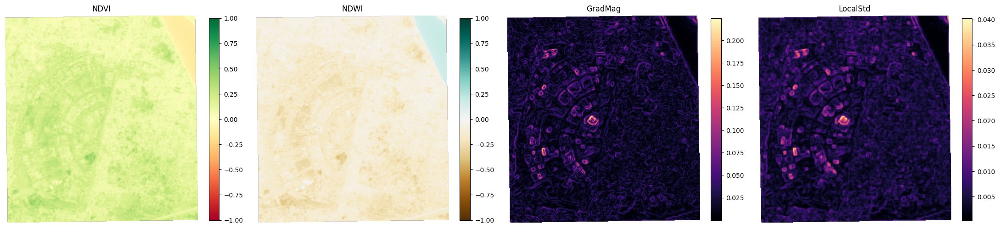

NDVI valid range: -0.14420193433761597 0.4841238260269165 | NDWI: -0.4168063998222351 0.21416805684566498


In [53]:
def build_features(st, cfg=CFG):
    # Return dict name -> 2-D float32 array; identical code is used for training and offline inference.
    r, v, B_ = st["raster"], st["valid"], st["B"]
    F = {}
    if st["spectral"]:
        for nm, k in zip(["Blue", "Green", "Red", "NIR"], ["blue", "green", "red", "nir"]): F[nm] = r[st["bidx"][k]]
        raw = list(F)
        F["NDVI"] = np.clip((F["NIR"] - F["Red"])/(F["NIR"] + F["Red"] + EPS), -1, 1).astype(np.float32)
        F["NDWI"] = np.clip((F["Green"] - F["NIR"])/(F["Green"] + F["NIR"] + EPS), -1, 1).astype(np.float32)
        lum = (F["Blue"] + F["Green"] + F["Red"])/3
    else:
        for i in range(B_): F[f"Ch{i+1}"] = r[i]
        raw = list(F); lum = r.mean(0)
    lum = lum.astype(np.float32).copy(); lum[~v] = np.median(lum[v])
    sm = cv2.GaussianBlur(lum, (0, 0), cfg["gauss_sigma"])
    F["GradMag"] = cv2.magnitude(cv2.Sobel(sm, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(sm, cv2.CV_32F, 0, 1, ksize=3))
    w = cfg["texture_window"]; m1 = ndi.uniform_filter(lum, w); m2 = ndi.uniform_filter(lum*lum, w)
    F["LocalStd"] = np.sqrt(np.maximum(m2 - m1*m1, 0)).astype(np.float32)
    return F, raw

F, RAW = build_features(S)
if spectral:
    fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
    for a, (k, cm, vr) in zip(axs, [("NDVI", "RdYlGn", (-1, 1)), ("NDWI", "BrBG", (-1, 1)), ("GradMag", "magma", None), ("LocalStd", "magma", None)]):
        d = np.ma.masked_where(~valid, F[k]); im = a.imshow(d, cmap=cm, vmin=None if vr is None else vr[0], vmax=None if vr is None else vr[1])
        a.set_title(k); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046)
    plt.tight_layout(); savefig("indices_and_spatial_features.png"); plt.show()
    print("NDVI valid range:", float(F["NDVI"][valid].min()), float(F["NDVI"][valid].max()),
          "| NDWI:", float(F["NDWI"][valid].min()), float(F["NDWI"][valid].max()))
else:
    print("Spectral indices skipped (input not verified as multispectral). Feature sets: raw channels and raw + spatial.")

## Feature groups — controlled ablation
* **A_raw** — original channels (the baseline of the earlier notebook family)
* **B_raw_indices** — A + NDVI + NDWI (spectral mode only)
* **C_raw_indices_spatial** — B + Sobel gradient magnitude + local standard deviation (DIP-derived spatial context)

For non-spectral inputs the sets are **A_raw** and **C_raw_spatial**. All sets use the **same** scaler type, K, solver settings, seed and the **same fixed evaluation pixels**.

In [54]:
SPATIAL = ["GradMag", "LocalStd"]
if spectral:
    FEATURE_SETS = {"A_raw": RAW, "B_raw_indices": RAW + ["NDVI", "NDWI"], "C_raw_indices_spatial": RAW + ["NDVI", "NDWI"] + SPATIAL}
else:
    FEATURE_SETS = {"A_raw": RAW, "C_raw_spatial": RAW + SPATIAL}
vidx = np.flatnonzero(valid.ravel()); NV = len(vidx)
Xs = {k: np.column_stack([F[f].ravel()[vidx] for f in fl]).astype(np.float32) for k, fl in FEATURE_SETS.items()}
for k, fl in FEATURE_SETS.items(): print(f"{k:24s} {Xs[k].shape}  {fl}")

# Fixed evaluation / stability pixel subsamples (identical for every feature set => comparable metrics)
ev_rng = np.random.default_rng(SEED + 7)
EVAL_IX = np.sort(ev_rng.choice(NV, min(CFG["eval_pixels"], NV), replace=False))
STAB_IX = np.sort(ev_rng.choice(NV, min(CFG["stability_pixels"], NV), replace=False))

A_raw                    (156656, 4)  ['Blue', 'Green', 'Red', 'NIR']
B_raw_indices            (156656, 6)  ['Blue', 'Green', 'Red', 'NIR', 'NDVI', 'NDWI']
C_raw_indices_spatial    (156656, 8)  ['Blue', 'Green', 'Red', 'NIR', 'NDVI', 'NDWI', 'GradMag', 'LocalStd']


## MiniBatch K-Means (fit on a sample, predict all valid pixels in batches)

A_raw | inertia (scaled space): 63065.6 | cluster sizes: [66661 52643  5169 32183]
B_raw_indices | inertia (scaled space): 93876.5 | cluster sizes: [52196 41600  5132 57728]
C_raw_indices_spatial | inertia (scaled space): 173619.9 | cluster sizes: [69677 76585  5320  5074]
saved GeoVision_DIP_Output/figures/cluster_maps_all_feature_sets.png


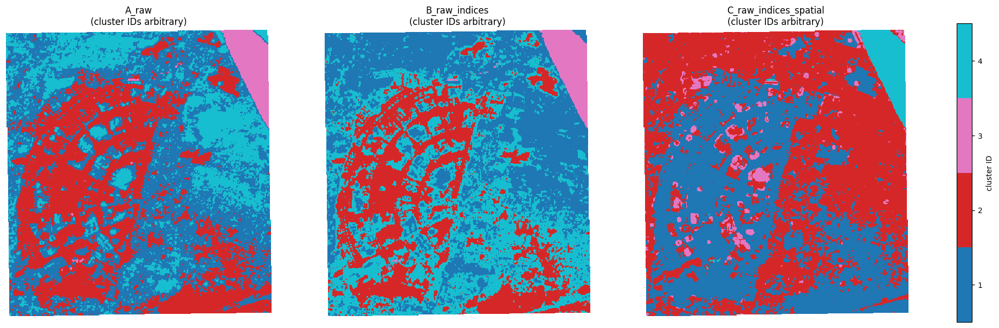

In [55]:
BATCH = 100000
def fit_model(X, k, seed, n_init=10):
    r = np.random.default_rng(seed); m = min(CFG["max_train"], len(X)); ix = r.choice(len(X), m, replace=False)
    sc = StandardScaler().fit(X[ix])
    km = MiniBatchKMeans(n_clusters=k, random_state=seed, batch_size=4096, n_init=n_init, max_iter=200).fit(sc.transform(X[ix]))
    return sc, km
def predict(sc, km, X):
    out = np.empty(len(X), np.int32)
    for s in range(0, len(X), BATCH): out[s:s+BATCH] = km.predict(sc.transform(X[s:s+BATCH]))
    return out

exp = {}
for key, X in Xs.items():
    sc, km = fit_model(X, K, SEED)
    lab = predict(sc, km, X)
    lm = np.zeros(H*W, np.uint8); lm[vidx] = lab + 1                      # 0 = NoData, 1..K = cluster IDs
    exp[key] = dict(scaler=sc, model=km, flat=lab, map=lm.reshape(H, W), features=FEATURE_SETS[key])
    print(key, "| inertia (scaled space):", round(float(km.inertia_), 1), "| cluster sizes:", np.bincount(lab, minlength=K))

cmap = plt.get_cmap("tab10", K)
fig, axs = plt.subplots(1, len(exp), figsize=(7*len(exp), 6.5), squeeze=False)
for a, (key, e) in zip(axs[0], exp.items()):
    im = a.imshow(np.ma.masked_where(e["map"] == 0, e["map"]), cmap=cmap, vmin=0.5, vmax=K+0.5, interpolation="nearest")
    a.set_title(f"{key}\n(cluster IDs arbitrary)"); a.axis("off")
plt.colorbar(im, ax=axs[0].tolist(), ticks=range(1, K+1), fraction=0.02, label="cluster ID")
savefig("cluster_maps_all_feature_sets.png"); plt.show()

## Separability (RQ3) — own space **and** common reference space
*Own-space* metrics use each set's own standardised feature space; they are **not** comparable across sets of different dimensionality.
*Common-space* metrics evaluate every label map in **one** space — the standardised raw bands (set A's space) — so the sets can be compared directly. Because A is optimised in that space, A has a built-in advantage there; the common-space score therefore shows what the other sets **trade** for spectral separability.
All metrics use the same fixed pixel subsample (`EVAL_IX`). Silhouette, DB (lower = better) and CH are internal measures, not accuracy.

In [56]:
def safe(f, X, l):
    return float(f(X, l)) if len(np.unique(l)) > 1 else np.nan
refsc = exp["A_raw"]["scaler"]; XA = Xs["A_raw"]
X_ref = refsc.transform(XA[EVAL_IX])
met = []
for key, e in exp.items():
    Xo = e["scaler"].transform(Xs[key][EVAL_IX]); l = e["flat"][EVAL_IX]
    met.append({"feature_set": key, "n_features": Xs[key].shape[1],
                "silhouette_own": safe(silhouette_score, Xo, l), "DB_own": safe(davies_bouldin_score, Xo, l), "CH_own": safe(calinski_harabasz_score, Xo, l),
                "silhouette_common": safe(silhouette_score, X_ref, l), "DB_common": safe(davies_bouldin_score, X_ref, l), "CH_common": safe(calinski_harabasz_score, X_ref, l)})
metrics_df = pd.DataFrame(met); display(metrics_df.round(4))
metrics_df.to_csv(TAB/"separability_metrics.csv", index=False)

,feature_set,n_features,silhouette_own,DB_own,CH_own,silhouette_common,DB_common,CH_common
0,A_raw,4,0.3638,0.8155,3812.6145,0.3638,0.8155,3812.6145
1,B_raw_indices,6,0.3402,0.8781,3876.7046,0.3179,0.9045,3201.0312
2,C_raw_indices_spatial,8,0.3637,0.8823,2224.7341,0.3361,1.4137,2167.7053


## Choice of K (justification, not a claim about the number of land-cover classes)
Silhouette and inertia versus K on the richest *spectral* feature set. K is a parameter, not a discovered truth.

,K,inertia,silhouette,DB
0,2,179460.2969,0.3930,0.9736
1,3,119179.3047,0.4383,0.6978
2,4,93792.0547,0.3405,0.8771
3,5,75688.8047,0.3257,0.8775
4,6,65022.3984,0.3085,0.8832
5,7,58984.3516,0.2828,0.9542
6,8,48481.4531,0.3201,0.8268


saved GeoVision_DIP_Output/figures/k_sweep.png


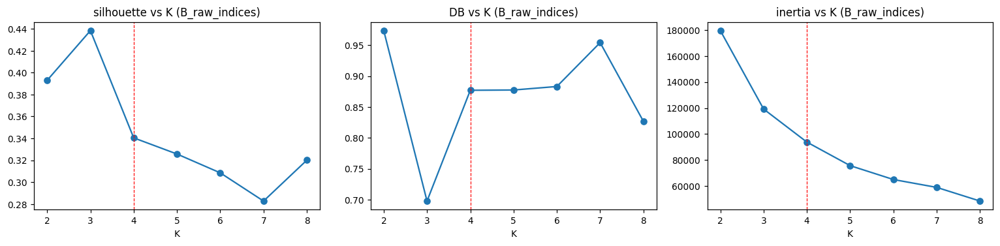

In [57]:
sweep_key = "B_raw_indices" if "B_raw_indices" in Xs else "A_raw"
sw = []
for k in CFG["k_sweep"]:
    sc_, km_ = fit_model(Xs[sweep_key], k, SEED, n_init=5)
    l_ = predict(sc_, km_, Xs[sweep_key][EVAL_IX]); Xo = sc_.transform(Xs[sweep_key][EVAL_IX])
    sw.append({"K": k, "inertia": float(km_.inertia_), "silhouette": safe(silhouette_score, Xo, l_), "DB": safe(davies_bouldin_score, Xo, l_)})
sweep_df = pd.DataFrame(sw); display(sweep_df.round(4)); sweep_df.to_csv(TAB/"k_sweep.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, c in zip(ax, ["silhouette", "DB", "inertia"]):
    a.plot(sweep_df["K"], sweep_df[c], "o-"); a.axvline(K, ls="--", c="r", lw=0.8); a.set_title(f"{c} vs K ({sweep_key})"); a.set_xlabel("K")
plt.tight_layout(); savefig("k_sweep.png"); plt.show()

## Seed stability (RQ4)
Each feature set is re-fitted several times with different random training samples and initialisations; stability is the mean pairwise **adjusted Rand index** (1 = identical partitions up to renaming) on a fixed pixel subsample.

In [58]:
def stability(X, k, runs, ix):
    L = []
    for s in range(runs):
        sc_, km_ = fit_model(X, k, SEED + 1000 + s, n_init=3); L.append(predict(sc_, km_, X[ix]))
    a = [adjusted_rand_score(x, y) for x, y in itertools.combinations(L, 2)]
    return float(np.mean(a)), float(np.std(a))
stab = []
for key in Xs:
    m, s_ = stability(Xs[key], K, CFG["stability_runs"], STAB_IX); stab.append({"feature_set": key, "stability_ARI_mean": m, "stability_ARI_std": s_})
stab_df = pd.DataFrame(stab); display(stab_df.round(4)); stab_df.to_csv(TAB/"seed_stability.csv", index=False)

,feature_set,stability_ARI_mean,stability_ARI_std
0,A_raw,0.6796,0.1362
1,B_raw_indices,0.4979,0.1607
2,C_raw_indices_spatial,0.5190,0.2221


## Agreement between feature sets
IDs are arbitrary, so label maps are matched to set A with the Hungarian algorithm before computing pixel agreement. ARI is invariant to renaming.

,set_1,set_2,ARI,pixel_agreement_after_matching_%
0,A_raw,B_raw_indices,0.4762,77.1346
1,A_raw,C_raw_indices_spatial,0.4141,68.1927
2,B_raw_indices,C_raw_indices_spatial,0.3875,61.8834


saved GeoVision_DIP_Output/figures/agreement_maps.png


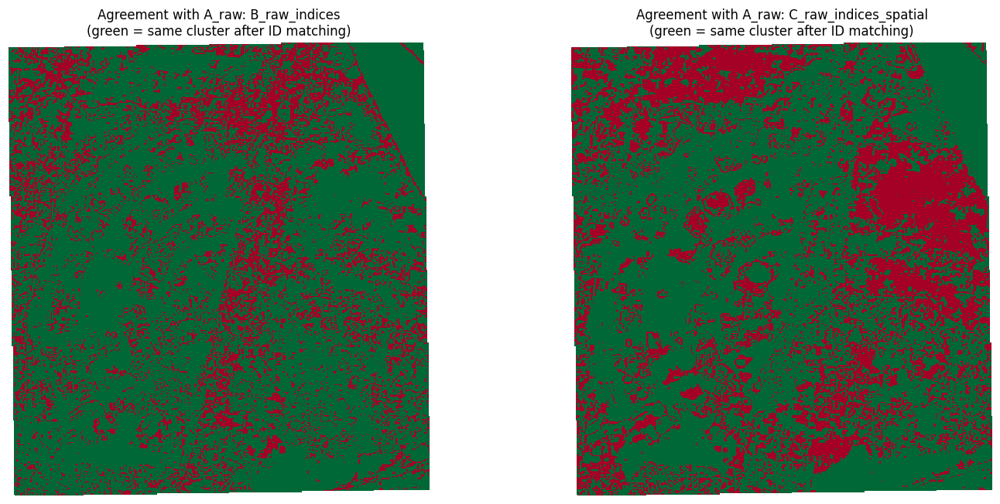

In [59]:
def align_to(ref, lab, k):
    C = np.zeros((k, k), int)
    for i in range(1, k+1):
        m = ref == i
        C[i-1] = np.bincount(lab[m], minlength=k+1)[1:k+1]
    r_, c_ = linear_sum_assignment(-C)
    lut = np.zeros(k+1, np.uint8)
    for a_, b_ in zip(r_, c_): lut[b_+1] = a_+1
    return lut[lab]
refmap = exp["A_raw"]["map"]
for key, e in exp.items(): e["aligned"] = align_to(refmap[valid], e["map"][valid], K)
ag = []
for a_, b_ in itertools.combinations(exp, 2):
    ga, gb = exp[a_]["map"][valid], exp[b_]["map"][valid]
    ag.append({"set_1": a_, "set_2": b_, "ARI": adjusted_rand_score(ga, gb),
               "pixel_agreement_after_matching_%": 100*float((align_to(ga, gb, K) == ga).mean())})
agree_df = pd.DataFrame(ag); display(agree_df.round(4)); agree_df.to_csv(TAB/"feature_set_agreement.csv", index=False)
if len(exp) > 1:
    fig, axs = plt.subplots(1, len(exp)-1, figsize=(7*(len(exp)-1), 6), squeeze=False)
    for a, key in zip(axs[0], [k_ for k_ in exp if k_ != "A_raw"]):
        al = np.zeros((H, W), np.uint8); al[valid] = exp[key]["aligned"]
        d = np.where(valid, (al == refmap).astype(float), np.nan)
        a.imshow(d, cmap="RdYlGn", vmin=0, vmax=1, interpolation="nearest"); a.set_title(f"Agreement with A_raw: {key}\n(green = same cluster after ID matching)"); a.axis("off")
    plt.tight_layout(); savefig("agreement_maps.png"); plt.show()

## Spatial organisation (RQ4, RQ5)
* **Components / patches** — 4-connected components per cluster; mean and largest patch; **fragmentation** = patches per 1000 valid pixels; **largest-patch index** (LPI) = largest patch as % of valid area.
* **Boundary density** — fraction of valid pixels having a 4-neighbour in a different cluster.
* **Canny enrichment (RQ5)** — fraction of cluster-boundary pixels lying within 1 px of a Canny edge, divided by the fraction of *all* valid pixels within 1 px of a Canny edge (chance level). Values > 1 mean cluster boundaries coincide with image edges more often than chance.
* **Majority filter** — a 3×3 mode filter is applied to every label map; comparing fragmentation before/after asks whether spatial-feature augmentation (set C) behaves like post-hoc smoothing.

In [ ]:
S4 = ndi.generate_binary_structure(2, 1)
edge_zone = cv2.dilate(edges.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0

def boundary_mask(lab):
    b = np.zeros(lab.shape, bool)
    for sa, sb in [((slice(0, -1), slice(None)), (slice(1, None), slice(None))),
                   ((slice(None), slice(0, -1)), (slice(None), slice(1, None)))]:
        d = (lab[sa] != lab[sb]) & (lab[sa] > 0) & (lab[sb] > 0); b[sa] |= d; b[sb] |= d
    return b

def majority_filter(lab, k, w):
    votes = np.stack([ndi.uniform_filter((lab == c).astype(np.float32), size=w) for c in range(1, k+1)])
    out = (votes.argmax(0) + 1).astype(np.uint8); out[lab == 0] = 0; return out

def patch_rows(lab, name, variant):
    rows = []
    for c in range(1, K+1):
        m = lab == c; cc, n = ndi.label(m, structure=S4)
        sz = np.bincount(cc.ravel())[1:] if n else np.array([0])
        rows.append({"feature_set": name, "variant": variant, "cluster_id": c, "pixel_count": int(m.sum()),
                     "pixel_percent": 100*m.sum()/NV, "components_4conn": int(n),
                     "mean_patch_pixels": float(sz.mean()), "largest_patch_pixels": int(sz.max())})
    return rows

def global_row(lab, name, variant, ref_lab=None):
    n_comp = 0; largest = 0
    for c in range(1, K+1):
        cc, n = ndi.label(lab == c, structure=S4); n_comp += n
        if n: largest = max(largest, int(np.bincount(cc.ravel())[1:].max()))
    bm = boundary_mask(lab) & valid_in
    base = float(edge_zone[valid_in].mean())
    r = {"feature_set": name, "variant": variant, "total_patches": n_comp,
         "patches_per_1000px": 1000*n_comp/NV, "mean_patch_pixels": NV/max(n_comp, 1),
         "largest_patch_index_%": 100*largest/NV, "boundary_density_%": 100*float(boundary_mask(lab)[valid].mean()),
         "canny_alignment_boundary": float(edge_zone[bm].mean()) if bm.any() else np.nan,
         "canny_alignment_chance": base,
         "canny_enrichment": float(edge_zone[bm].mean())/base if bm.any() and base > 0 else np.nan}
    r["pixel_agreement_with_unfiltered_%"] = 100*float((lab[valid] == ref_lab[valid]).mean()) if ref_lab is not None else 100.0
    return r

patch_rows_all, glob_rows = [], []
for key, e in exp.items():
    e["majority"] = majority_filter(e["map"], K, CFG["majority_window"])
    patch_rows_all += patch_rows(e["map"], key, "raw labels")
    glob_rows += [global_row(e["map"], key, "raw labels"), global_row(e["majority"], key, f"majority {CFG['majority_window']}x{CFG['majority_window']}", e["map"])]
patch_df, spatial_df = pd.DataFrame(patch_rows_all), pd.DataFrame(glob_rows)
display(patch_df[patch_df.variant == "raw labels"].round(3)); display(spatial_df.round(3))
patch_df.to_csv(TAB/"cluster_patch_summary.csv", index=False); spatial_df.to_csv(TAB/"spatial_organisation_metrics.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
pv = spatial_df.pivot(index="feature_set", columns="variant", values="patches_per_1000px"); pv.plot.bar(ax=ax[0], rot=15); ax[0].set_title("Fragmentation (patches / 1000 px)")
pv = spatial_df[spatial_df.variant == "raw labels"].set_index("feature_set")["canny_enrichment"]; pv.plot.bar(ax=ax[1], rot=15, color="tab:green"); ax[1].axhline(1, c="k", ls="--", lw=0.8); ax[1].set_title("Canny enrichment of cluster boundaries (1 = chance)")
pv = spatial_df[spatial_df.variant == "raw labels"].set_index("feature_set")["boundary_density_%"]; pv.plot.bar(ax=ax[2], rot=15, color="tab:purple"); ax[2].set_title("Boundary density (%)")
plt.tight_layout(); savefig("spatial_metrics.png"); plt.show()

## NDWI-mask consistency check (spectral mode; **not validation**)
An Otsu threshold on NDWI gives a candidate-water mask (opened and closed with a 3×3 ellipse). We then measure the overlap (IoU) between that mask and the highest-NDWI cluster of every feature set. Both come from the same bands, so this only shows internal consistency.

Otsu NDWI threshold = -0.137 | candidate pixels = 70,385 (44.93% of valid)


,feature_set,highest_NDWI_cluster,mean_NDWI_of_that_cluster,IoU_with_NDWI_mask
0,A_raw,3,0.1532,0.0734
1,B_raw_indices,3,0.1558,0.0729
2,C_raw_indices_spatial,4,0.1572,0.0721


saved GeoVision_DIP_Output/figures/ndwi_mask_morphology.png


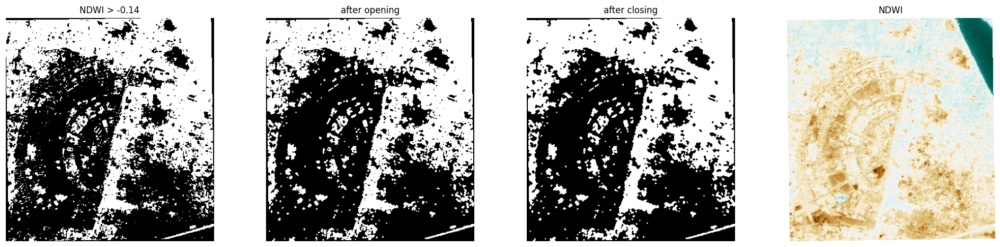

In [ ]:
water_df = pd.DataFrame()
if spectral:
    nd = F["NDWI"]; u = np.uint8(np.clip((nd[valid] + 1)/2, 0, 1)*255).reshape(-1, 1)
    thr_u, _ = cv2.threshold(u, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU); thr = float(thr_u)/255*2 - 1
    cand = ((nd > thr) & valid).astype(np.uint8); ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    opened = cv2.morphologyEx(cand, cv2.MORPH_OPEN, ker); closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, ker).astype(bool)
    print(f"Otsu NDWI threshold = {thr:.3f} | candidate pixels = {closed.sum():,} ({100*closed.sum()/NV:.2f}% of valid)")
    rows = []
    for key, e in exp.items():
        means = [float(nd[(e['map'] == c) & valid].mean()) if ((e['map'] == c) & valid).any() else -9 for c in range(1, K+1)]
        c = int(np.argmax(means)) + 1; m = (e["map"] == c); iou = float((m & closed).sum()/max((m | closed).sum(), 1))
        rows.append({"feature_set": key, "highest_NDWI_cluster": c, "mean_NDWI_of_that_cluster": means[c-1], "IoU_with_NDWI_mask": iou})
    water_df = pd.DataFrame(rows); display(water_df.round(4)); water_df.to_csv(TAB/"ndwi_mask_consistency.csv", index=False)
    fig, axs = plt.subplots(1, 4, figsize=(18, 4.3))
    for a, (im, t) in zip(axs, [(cand, f"NDWI > {thr:.2f}"), (opened, "after opening"), (closed, "after closing"), (np.ma.masked_where(~valid, nd), "NDWI")]):
        a.imshow(im, cmap="gray" if t != "NDWI" else "BrBG"); a.set_title(t); a.axis("off")
    plt.tight_layout(); savefig("ndwi_mask_morphology.png"); plt.show()
else:
    print("Skipped: no verified NIR/Green bands.")

## Cluster spectral summaries and projected-CRS area
Means/stds use **original reflectance**, not display-stretched values. Hints are *relative* and exploratory (highest-NDVI cluster, highest-NDWI cluster); they are not land-cover labels. Area is computed only for a projected CRS using the affine pixel area at the working resolution.

Area method: projected CRS affine pixel area (working resolution) | pixel area (m2): 83.80505350251086


,feature_set,cluster_id,pixel_count,pixel_percent,area_ha,Blue_mean,Blue_std,Green_mean,Green_std,Red_mean,Red_std,NIR_mean,NIR_std,NDVI_mean,NDWI_mean,"relative_hint (exploratory, not ground truth)"
0,A_raw,1,66661,42.5525,558.6529,0.1605,0.0048,0.1686,0.0048,0.1685,0.0074,0.2218,0.0218,0.1342,-0.1336,other / mixed response
1,A_raw,2,52643,33.6042,441.1749,0.1460,0.0059,0.1531,0.0064,0.1456,0.0084,0.2283,0.0239,0.2188,-0.1947,"highest NDVI cluster (most vegetation-like, re..."
2,A_raw,3,5169,3.2996,43.3188,0.1461,0.0061,0.1529,0.0064,0.1361,0.0077,0.1129,0.0137,-0.0956,0.1532,"highest NDWI cluster (water-like, relative)"
3,A_raw,4,32183,20.5437,269.7098,0.1750,0.0076,0.1846,0.0089,0.1902,0.0122,0.2283,0.0240,0.0891,-0.1036,other / mixed response
4,B_raw_indices,1,52196,33.3189,437.4289,0.1709,0.0082,0.1796,0.0096,0.1838,0.0127,0.2176,0.0210,0.0829,-0.0941,other / mixed response
5,B_raw_indices,2,41600,26.5550,348.6290,0.1447,0.0059,0.1518,0.0065,0.1434,0.0078,0.2328,0.0245,0.2354,-0.2082,"highest NDVI cluster (most vegetation-like, re..."
6,B_raw_indices,3,5132,3.2760,43.0088,0.1463,0.0064,0.1531,0.0068,0.1362,0.0080,0.1123,0.0123,-0.0979,0.1558,"highest NDWI cluster (water-like, relative)"
7,B_raw_indices,4,57728,36.8502,483.7898,0.1573,0.0051,0.1656,0.0058,0.1640,0.0086,0.2272,0.0221,0.1598,-0.1547,other / mixed response
8,C_raw_indices_spatial,1,69677,44.4777,583.9285,0.1487,0.0072,0.1562,0.0079,0.1497,0.0107,0.2320,0.0234,0.2137,-0.1931,"highest NDVI cluster (most vegetation-like, re..."
9,C_raw_indices_spatial,2,76585,48.8874,641.8210,0.1665,0.0078,0.1749,0.0084,0.1774,0.0113,0.2181,0.0196,0.1016,-0.1084,other / mixed response


saved GeoVision_DIP_Output/figures/cluster_areas.png


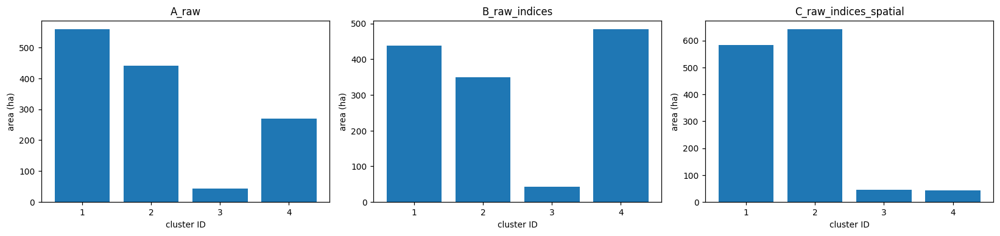

In [ ]:
def pixel_area_m2(transform, crs):
    if transform is None or crs is None: return None, "not calculated: no georeferencing"
    c = CRS.from_user_input(crs)
    if not c.is_projected: return None, "not calculated: geographic CRS (reproject to a metric CRS first)"
    f = c.axis_info[0].unit_conversion_factor if c.axis_info else 1.0
    return abs(transform.a*transform.e - transform.b*transform.d)*f*f, "projected CRS affine pixel area (working resolution)"
pix_area, area_method = pixel_area_m2(S["work_transform"], S["crs"]); print("Area method:", area_method, "| pixel area (m2):", pix_area)

rows = []
for key, e in exp.items():
    means_ndvi = {}; means_ndwi = {}
    for c in range(1, K+1):
        m = (e["map"] == c) & valid; n = int(m.sum())
        row = {"feature_set": key, "cluster_id": c, "pixel_count": n, "pixel_percent": 100*n/NV}
        if pix_area: row["area_ha"] = n*pix_area/1e4
        for f in RAW: row[f"{f}_mean"] = float(F[f][m].mean()) if n else np.nan; row[f"{f}_std"] = float(F[f][m].std()) if n else np.nan
        if spectral:
            row["NDVI_mean"] = float(F["NDVI"][m].mean()) if n else np.nan; row["NDWI_mean"] = float(F["NDWI"][m].mean()) if n else np.nan
        rows.append(row)
cs = pd.DataFrame(rows)
if spectral:
    cs["relative_hint (exploratory, not ground truth)"] = "other / mixed response"
    for key in exp:
        sub = cs[cs.feature_set == key]
        iv, iw = sub["NDVI_mean"].idxmax(), sub["NDWI_mean"].idxmax()
        cs.loc[iv, "relative_hint (exploratory, not ground truth)"] = "highest NDVI cluster (most vegetation-like, relative)"
        cs.loc[iw, "relative_hint (exploratory, not ground truth)"] = ("highest NDWI cluster (water-like, relative)" if cs.loc[iw, "NDWI_mean"] > 0
                                                                       else "highest NDWI cluster but index mean <= 0 (open water unlikely)")
display(cs.round(4)); cs.to_csv(TAB/"cluster_spectral_area_summary.csv", index=False)
fig, axs = plt.subplots(1, len(exp), figsize=(5*len(exp), 3.6), squeeze=False)
for a, key in zip(axs[0], exp):
    s_ = cs[cs.feature_set == key]; a.bar(s_["cluster_id"].astype(str), s_["area_ha"] if pix_area else s_["pixel_count"]); a.set_title(key)
    a.set_ylabel("area (ha)" if pix_area else "pixels"); a.set_xlabel("cluster ID")
plt.tight_layout(); savefig("cluster_areas.png"); plt.show()

## Exports: georeferenced label rasters, model bundles, reload verification
Each bundle stores everything needed to repeat prediction offline: scaler, model, feature schema, K, seed, preprocessing configuration and reflectance divisor.

In [ ]:
if S["work_transform"] is not None:
    for key, e in exp.items():
        prof = dict(driver="GTiff", height=H, width=W, count=1, dtype="uint8", crs=S["crs"], transform=S["work_transform"], nodata=0, compress="lzw")
        with rasterio.open(RAS/f"{key}_cluster_labels.tif", "w", **prof) as dst:
            dst.write(e["map"], 1); dst.update_tags(project="GeoVision-DIP", feature_set=key, n_clusters=str(K), seed=str(SEED),
                                                    note="0=NoData; unsupervised spectral clusters, not validated classes")
        print("saved", RAS/f"{key}_cluster_labels.tif")
else:
    print("No GeoTIFF export (input has no CRS); PNG maps are saved instead.")
for key, e in exp.items():
    plt.imsave(FIG/f"{key}_cluster_map.png", np.ma.masked_where(e["map"] == 0, e["map"]), cmap=cmap, vmin=0.5, vmax=K+0.5)

reload_checks = {}
for key, e in exp.items():
    bundle = dict(scaler=e["scaler"], model=e["model"], feature_names=e["features"], feature_set=key, n_clusters=K, seed=SEED,
                  spectral=spectral, band_map=S["band_map"], reflectance_divisor=S["divisor"], cfg=CFG, eps=EPS)
    p = MOD/f"{key}_bundle.joblib"; joblib.dump(bundle, p); L = joblib.load(p)
    n = min(10000, NV); same = bool(np.array_equal(e["model"].predict(e["scaler"].transform(Xs[key][:n])), L["model"].predict(L["scaler"].transform(Xs[key][:n]))))
    reload_checks[key] = dict(file=str(p), identical_after_reload=same, test_pixels=n); print(key, "reload identical:", same)
assert all(v["identical_after_reload"] for v in reload_checks.values()), "Reload verification failed"

saved GeoVision_DIP_Output/rasters/A_raw_cluster_labels.tif
saved GeoVision_DIP_Output/rasters/B_raw_indices_cluster_labels.tif
saved GeoVision_DIP_Output/rasters/C_raw_indices_spatial_cluster_labels.tif
A_raw reload identical: True
B_raw_indices reload identical: True
C_raw_indices_spatial reload identical: True


## Offline inference check
`apply_bundle` re-reads the image, rebuilds the features with the **stored** preprocessing and predicts using only the saved bundle — no refitting, no network. Here it is run on the same input to confirm exact reproduction; for a genuinely air-gapped test, copy the bundle, this function, and an image to an offline machine.

In [ ]:
def apply_bundle(bundle_path, image_paths):
    b = joblib.load(bundle_path)
    st = prepare(image_paths, spectral_mode="on" if b["spectral"] else "off", band_map=b["band_map"] or BAND_MAP, cfg=b["cfg"], divisor=b["reflectance_divisor"], verbose=False)
    Fx, _ = build_features(st, b["cfg"]); vi = np.flatnonzero(st["valid"].ravel())
    X = np.column_stack([Fx[f].ravel()[vi] for f in b["feature_names"]]).astype(np.float32)
    lab = np.zeros(st["H"]*st["W"], np.uint8); lab[vi] = predict(b["scaler"], b["model"], X) + 1
    return lab.reshape(st["H"], st["W"])

offline = {}
for key, e in exp.items():
    lab2 = apply_bundle(MOD/f"{key}_bundle.joblib", paths); offline[key] = bool(np.array_equal(lab2, e["map"]))
    print(f"{key}: offline re-inference identical to in-notebook labels -> {offline[key]}")

A_raw: offline re-inference identical to in-notebook labels -> True
B_raw_indices: offline re-inference identical to in-notebook labels -> True
C_raw_indices_spatial: offline re-inference identical to in-notebook labels -> True


## Results digest and reproducibility record
The digest contains **only numbers computed in this run** (no interpretive claims) — paste them into the IEEE paper and write the interpretation yourself, within the stated limitations.

In [ ]:
def tbl(title, name, nd=4):
    d = globals().get(name)
    return [title, d.round(nd).to_string(index=False) if d is not None and len(d) else f"[not available: run the cell that creates {name}]", ""]
missing = [n for n in ["enh_df","edge_df","metrics_df","stab_df","sweep_df","spatial_df","agree_df"] if n not in globals()]
if missing: print("WARNING - these sections did not run, scroll up to the first cell with an error:", missing)
lines = ["GeoVision-DIP results digest", "="*60,
         f"Generated: {datetime.datetime.now().isoformat(timespec='seconds')}",
         f"Input: {info['source']}", f"CRS: {S['crs']} | native shape (bands,rows,cols): ({B},{H0},{W0}) | working shape: ({B},{H},{W})",
         f"Valid pixels: {NV:,} | non-finite excluded: {S['n_nonfinite']:,} | all-zero excluded: {S['n_allzero']:,}",
         f"Spectral mode: {spectral} | reflectance divisor: {S['divisor']:g} | K={K} | seed={SEED}",
         f"Area method: {globals().get('area_method')} | pixel area m2: {globals().get('pix_area')}", ""]
lines += tbl("Enhancement metrics:", "enh_df") + tbl("Canny edge density (original vs CLAHE):", "edge_df", 3)
lines += tbl("Separability (own space not comparable across sets; common space is):", "metrics_df") + tbl("Seed stability (ARI):", "stab_df")
lines += tbl("K-sweep:", "sweep_df") + tbl("Spatial organisation:", "spatial_df", 3) + tbl("Agreement between feature sets:", "agree_df")
if len(globals().get("water_df", [])): lines += tbl("NDWI-mask consistency (not validation):", "water_df")
lines += ["Caveat: clusters are exploratory image-pattern groups, not validated semantic classes; no accuracy is claimed."]
digest = "\n".join(lines); (OUT/"results_digest.txt").write_text(digest); print(digest)
rec = lambda n: globals()[n].to_dict("records") if n in globals() else None
meta = dict(project="GeoVision-DIP", generated=datetime.datetime.now().isoformat(timespec="seconds"),
            input_files=info["source"], crs=str(S["crs"]), native_shape=[B, H0, W0], working_shape=[B, H, W],
            valid_pixels=int(NV), nonfinite_excluded=S["n_nonfinite"], allzero_excluded=S["n_allzero"],
            spectral_mode=spectral, band_map=S["band_map"], reflectance_divisor=S["divisor"], config=CFG,
            feature_sets=FEATURE_SETS, area_method=globals().get("area_method"), pixel_area_m2=globals().get("pix_area"),
            separability=rec("metrics_df"), stability=rec("stab_df"), spatial=rec("spatial_df"),
            reload_checks=globals().get("reload_checks"), offline_inference_identical=globals().get("offline"),
            versions=dict(python=sys.version.split()[0], numpy=np.__version__, sklearn=sklearn.__version__, opencv=cv2.__version__, rasterio=rasterio.__version__),
            caveat="Unsupervised clusters are exploratory image-pattern groups, not validated semantic classes. No accuracy claimed.")
(OUT/"run_metadata.json").write_text(json.dumps(meta, indent=2, default=str)); print("saved", OUT/"run_metadata.json")

WARNING - these sections did not run, scroll up to the first cell with an error: ['spatial_df']
GeoVision-DIP results digest
Generated: 2026-11-11T20:35:56
Input: ['Sentinel2_BHU_4band.tif']
CRS: EPSG:32644 | native shape (bands,rows,cols): (4,416,386) | working shape: (4,416,386)
Valid pixels: 156,656 | non-finite excluded: 0 | all-zero excluded: 3,920
Spectral mode: True | reflectance divisor: 1 | K=4 | seed=42
Area method: projected CRS affine pixel area (working resolution) | pixel area m2: 83.80505350251086

Enhancement metrics:
            method  entropy_bits  rms_contrast_std  dynamic_range_p98_p2   mean
          Original        7.8587            0.2418                0.9581 0.4710
             Gamma        7.8203            0.2324                0.9378 0.5337
Hist. equalisation        7.6714            0.2917                0.9694 0.4970
             CLAHE        7.9412            0.2646                0.9569 0.4997

Canny edge density (original vs CLAHE):
                   

## Submission helper (individual files — **no ZIP**)
Set `PREFIX` to your `Name_RollNumber_` pattern; this copies the key outputs, one by one, into `submission_files/` with that prefix. `DOWNLOAD=True` triggers individual browser downloads in Colab (allow multiple downloads when prompted).

In [ ]:
PREFIX = "Name_RollNumber_"      # <-- edit
DOWNLOAD = False
SUB = OUT/"submission_files"; SUB.mkdir(exist_ok=True)
keep = [FIG/"cluster_maps_all_feature_sets.png", FIG/"composites.png", FIG/"enhancement_comparison.png", FIG/"spatial_filters.png",
        FIG/"indices_and_spatial_features.png", FIG/"spatial_metrics.png", FIG/"k_sweep.png", FIG/"agreement_maps.png",
        TAB/"separability_metrics.csv", TAB/"seed_stability.csv", TAB/"spatial_organisation_metrics.csv",
        TAB/"cluster_spectral_area_summary.csv", OUT/"results_digest.txt", OUT/"run_metadata.json"]
for f in keep:
    if f.exists(): shutil.copy2(f, SUB/(PREFIX + f.name))
print(*sorted(p.name for p in SUB.iterdir()), sep="\n")
if DOWNLOAD:
    from google.colab import files
    for p in sorted(SUB.iterdir()): files.download(str(p))

Name_RollNumber_agreement_maps.png
Name_RollNumber_cluster_maps_all_feature_sets.png
Name_RollNumber_cluster_spectral_area_summary.csv
Name_RollNumber_composites.png
Name_RollNumber_enhancement_comparison.png
Name_RollNumber_indices_and_spatial_features.png
Name_RollNumber_k_sweep.png
Name_RollNumber_results_digest.txt
Name_RollNumber_run_metadata.json
Name_RollNumber_seed_stability.csv
Name_RollNumber_separability_metrics.csv
Name_RollNumber_spatial_filters.png


# **BENGALURU**

In [ ]:
from google.colab import files
import rasterio
import numpy as np
from pathlib import Path

uploaded = files.upload()
INPUT_DIR = Path("/content/")
# Identify the four uploaded bands
band_files = {}
for name in uploaded:
    lower = name.lower()
    for band in ["b02", "b03", "b04", "b08"]:
        if band in lower and lower.endswith((".tif", ".tiff")):
            band_files[band] = name

required = ["b02", "b03", "b04", "b08"]

if not all(b in band_files for b in required):
    raise ValueError(f"Missing bands. Found: {list(band_files)}")

# Stack bands in the correct order
band_order = ["b02", "b03", "b04", "b08"]
arrays = []

with rasterio.open(band_files["b02"]) as src:
    profile = src.profile.copy()
    reference_shape = (src.height, src.width)
    reference_transform = src.transform
    reference_crs = src.crs

for band in band_order:
    with rasterio.open(band_files[band]) as src:
        assert (src.height, src.width) == reference_shape
        assert src.transform == reference_transform
        assert src.crs == reference_crs
        arrays.append(src.read(1).astype(np.float32))

# Create four-band GeoTIFF
profile.update(
    driver="GTiff",
    count=4,
    dtype="float32",
    compress="lzw"
)

RASTER_PATH = str(INPUT_DIR / "Sentinel2_Bengaluru_4band.tif")

with rasterio.open(RASTER_PATH, "w", **profile) as dst:
    for i, arr in enumerate(arrays, start=1):
        dst.write(arr, i)
        dst.set_band_description(i, band_order[i-1].upper())

print("Four-band raster created:", RASTER_PATH)
print("Band order: B02, B03, B04, B08")

Saving 2026-10-29-00_00_2026-10-29-23_59_Sentinel-2_L2A_B02_(Raw).tiff to 2026-10-29-00_00_2026-10-29-23_59_Sentinel-2_L2A_B02_(Raw).tiff
Saving 2026-10-29-00_00_2026-10-29-23_59_Sentinel-2_L2A_B03_(Raw).tiff to 2026-10-29-00_00_2026-10-29-23_59_Sentinel-2_L2A_B03_(Raw).tiff
Saving 2026-10-29-00_00_2026-10-29-23_59_Sentinel-2_L2A_B04_(Raw).tiff to 2026-10-29-00_00_2026-10-29-23_59_Sentinel-2_L2A_B04_(Raw).tiff
Saving 2026-10-29-00_00_2026-10-29-23_59_Sentinel-2_L2A_B08_(Raw).tiff to 2026-10-29-00_00_2026-10-29-23_59_Sentinel-2_L2A_B08_(Raw).tiff
Four-band raster created: /content/Sentinel2_Bengaluru_4band.tif
Band order: B02, B03, B04, B08


In [ ]:
IMG_EXT = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}
BAND_KEYS = ["b02", "b03", "b04", "b08"]

def find_inputs():
    if INPUT_PATHS: return [Path(p) for p in INPUT_PATHS]
    env = os.environ.get("GEOVISION_INPUT")            # optional, for local/headless runs
    if env: return [Path(p) for p in env.split(os.pathsep)]
    try:
        from google.colab import files
        up = files.upload()
        return [Path(k) for k in up]
    except ImportError:
        return sorted(p for p in Path("input").glob("*") if p.suffix.lower() in IMG_EXT)

paths = find_inputs()
if not paths: raise FileNotFoundError("No input found. Upload files in Colab or set INPUT_PATHS.")
for p in paths:
    if not p.exists(): raise FileNotFoundError(p)
print("Input files:")
for p in paths: print("  ", p.name)

Saving Sentinel2_Bengaluru_4band.tif to Sentinel2_Bengaluru_4band.tif
Input files:
   Sentinel2_Bengaluru_4band.tif


In [ ]:
def band_key(path):
    n = path.name.lower()
    for k in BAND_KEYS:
        if re.search(rf"(?<![a-z0-9]){k}(?![a-z0-9])", n): return k
    return None

def load_input(paths):
    info = dict(source=[p.name for p in paths], geo=False, crs=None, transform=None,
                spectral_verified=False, band_map=None, descriptions=None)
    keys = {band_key(p): p for p in paths if band_key(p)}
    if all(k in keys for k in BAND_KEYS):                       # four separate Sentinel-2 files
        with rasterio.open(keys["b02"]) as ref:
            shp, tf, crs = (ref.height, ref.width), ref.transform, ref.crs
        arrs = []
        for k in BAND_KEYS:
            with rasterio.open(keys[k]) as s:
                if (s.height, s.width) != shp or s.transform != tf or s.crs != crs:
                    raise ValueError(f"{k.upper()} is not aligned with B02 (size/transform/CRS). Align bands first.")
                arrs.append(s.read(1, masked=True).astype(np.float32).filled(np.nan))
        info.update(geo=crs is not None, crs=crs, transform=tf, spectral_verified=True,
                    band_map={"blue": 1, "green": 2, "red": 3, "nir": 4},
                    descriptions=[k.upper() for k in BAND_KEYS])
        return np.stack(arrs).astype(np.float32), info
    p = paths[0]
    if len(paths) > 1: print("Note: using only the first file:", p.name)
    if p.suffix.lower() in (".tif", ".tiff"):
        try:
            with rasterio.open(p) as s:
                arr = s.read(masked=True).astype(np.float32).filled(np.nan)
                desc = [str(d).upper() if d else None for d in s.descriptions]
                info.update(geo=s.crs is not None, crs=s.crs, transform=s.transform, descriptions=desc)
                if desc[:4] == ["B02", "B03", "B04", "B08"]:
                    info.update(spectral_verified=True, band_map={"blue": 1, "green": 2, "red": 3, "nir": 4})
            return arr, info
        except Exception as e:
            print("rasterio could not read this TIFF, trying Pillow:", e)
    im = Image.open(p)
    if im.mode in ("P", "RGBA", "CMYK", "LA"): im = im.convert("RGB")
    a = np.array(im)
    a = a[None] if a.ndim == 2 else np.moveaxis(a[..., :3], -1, 0)
    return a.astype(np.float32), info

def prepare(paths, spectral_mode=SPECTRAL, band_map=BAND_MAP, cfg=CFG, divisor=None, verbose=True):
    raster, info = load_input(paths)
    B, H0, W0 = raster.shape
    valid0 = np.all(np.isfinite(raster), axis=0)
    n_nonfinite = int((~valid0).sum())
    n_allzero = 0
    if info["geo"]:
        allzero = np.all(raster == 0, axis=0) & valid0
        n_allzero = int(allzero.sum()); valid0 &= ~allzero
    H, W, md_ = H0, W0, cfg["max_dimension"]
    if md_ and max(H0, W0) > md_:
        s = md_ / max(H0, W0); W, H = max(1, round(W0*s)), max(1, round(H0*s))
        filled = np.nan_to_num(raster, nan=0.0)
        raster = np.stack([cv2.resize(b, (W, H), interpolation=cv2.INTER_AREA) for b in filled])
        valid = cv2.resize(valid0.astype(np.float32), (W, H), interpolation=cv2.INTER_AREA) > 0.999
    else:
        valid = valid0
    raster = np.where(valid[None], np.nan_to_num(raster, nan=0.0), 0).astype(np.float32)
    if not valid.any(): raise ValueError("No valid pixels.")
    if spectral_mode == "off": spectral = False
    elif spectral_mode == "on": spectral = B >= 4
    else: spectral = bool(info["spectral_verified"])
    bm = info["band_map"] or band_map
    bidx = {k: v-1 for k, v in bm.items()}
    if spectral:
        if max(bidx.values()) >= B or min(bidx.values()) < 0: raise ValueError("BAND_MAP invalid for this raster.")
        if divisor is None:
            divisor = 10000.0 if np.percentile(raster[:, valid], 99) > 2 else 1.0
        raster = raster / divisor
    else:
        divisor = 1.0
    work_tf = (info["transform"] * Affine.scale(W0/W, H0/H)) if info["geo"] else None
    st = dict(raster=raster, valid=valid, spectral=spectral, bidx=bidx, divisor=divisor, info=info,
              B=B, H=H, W=W, H0=H0, W0=W0, work_transform=work_tf, crs=info["crs"],
              n_nonfinite=n_nonfinite, n_allzero=n_allzero, band_map=bm)
    if verbose:
        print(f"Native shape (bands,rows,cols): ({B},{H0},{W0}) | working: ({B},{H},{W})")
        print(f"Invalid pixels: non-finite={n_nonfinite:,}, all-zero={n_allzero:,} | valid={int(valid.sum()):,} ({100*valid.mean():.2f}%)")
        print(f"CRS: {info['crs']} | spectral mode: {spectral} | reflectance divisor: {divisor:g}")
        if info["geo"]: print("Native pixel size (m):", abs(info['transform'].a), abs(info['transform'].e))
    return st

S = prepare(paths)
raster, valid, spectral, bidx = S["raster"], S["valid"], S["spectral"], S["bidx"]
B, H, W, H0, W0 = S["B"], S["H"], S["W"], S["H0"], S["W0"]
info = S["info"]

Native shape (bands,rows,cols): (4,2153,2500) | working: (4,1722,2000)
Invalid pixels: non-finite=0, all-zero=106,942 | valid=3,372,698 (97.93%)
CRS: EPSG:32643 | spectral mode: True | reflectance divisor: 1
Native pixel size (m): 13.445160541199986 13.404418038550801


saved GeoVision_DIP_Output/figures/composites.png


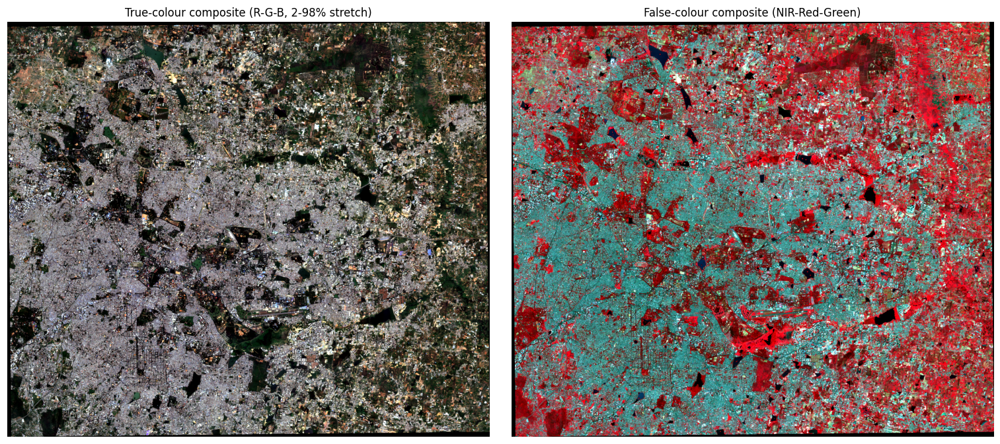

,channel,min,max,mean,std,p2,p98
0,Blue,0.0087,1.4442,0.0885,0.0500,0.0263,0.2110
1,Green,0.0116,1.4782,0.1143,0.0517,0.0425,0.2406
2,Red,0.0071,1.4869,0.1179,0.0657,0.0261,0.2708
3,NIR,0.0070,1.4888,0.2800,0.0704,0.1407,0.4300


saved GeoVision_DIP_Output/figures/channel_histograms.png


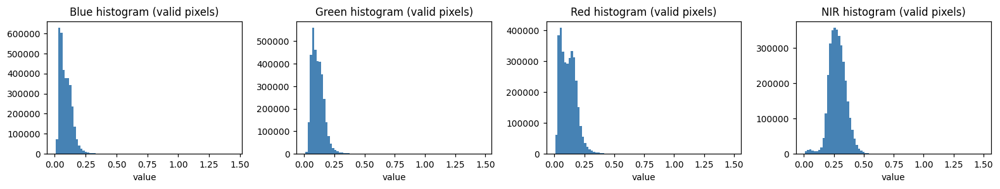

In [ ]:
def stretch(a, mask, lo=2, hi=98):
    v = a[mask]; out = np.zeros(a.shape, np.float32)
    if v.size:
        p, q = np.percentile(v, [lo, hi])
        if q > p: out = np.clip((a - p)/(q - p), 0, 1).astype(np.float32)
    out[~mask] = 0
    return out

def display_rgb(st):
    r, v = st["raster"], st["valid"]
    if st["spectral"]:   idx = [st["bidx"]["red"], st["bidx"]["green"], st["bidx"]["blue"]]
    elif st["B"] >= 3:   idx = [0, 1, 2]
    else:                idx = [0, 0, 0]
    return np.stack([stretch(r[i], v) for i in idx], -1), idx

rgb, rgb_idx = display_rgb(S)
fig, ax = plt.subplots(1, 2 if (spectral) else 1, figsize=(14 if spectral else 7, 6), squeeze=False); ax = ax[0]
ax[0].imshow(rgb); ax[0].set_title("True-colour composite (R-G-B, 2-98% stretch)" if spectral else "Input image (display-stretched)"); ax[0].axis("off")
if spectral:
    fc = np.stack([stretch(raster[bidx["nir"]], valid), stretch(raster[bidx["red"]], valid), stretch(raster[bidx["green"]], valid)], -1)
    ax[1].imshow(fc); ax[1].set_title("False-colour composite (NIR-Red-Green)"); ax[1].axis("off")
plt.tight_layout(); savefig("composites.png"); plt.show()

names_ch = ["Blue", "Green", "Red", "NIR"] if spectral else [f"Ch{i+1}" for i in range(B)]
chan_order = [bidx[k] for k in ["blue", "green", "red", "nir"]] if spectral else list(range(B))
rows = []
for nm, i in zip(names_ch, chan_order):
    v = raster[i][valid]
    rows.append(dict(channel=nm, min=v.min(), max=v.max(), mean=v.mean(), std=v.std(),
                     p2=np.percentile(v, 2), p98=np.percentile(v, 98)))
band_stats = pd.DataFrame(rows).round(4); display(band_stats)
band_stats.to_csv(TAB/"image_channel_statistics.csv", index=False)
fig, axs = plt.subplots(1, len(chan_order), figsize=(3.6*len(chan_order), 2.8), squeeze=False)
for a, nm, i in zip(axs[0], names_ch, chan_order):
    a.hist(raster[i][valid], bins=80, color="steelblue"); a.set_title(f"{nm} histogram (valid pixels)"); a.set_xlabel("value")
plt.tight_layout(); savefig("channel_histograms.png"); plt.show()

,method,entropy_bits,rms_contrast_std,dynamic_range_p98_p2,mean
0,Original,7.7231,0.2417,0.9619,0.3588
1,Gamma,7.8024,0.2400,0.9579,0.4226
2,Hist. equalisation,7.5493,0.2932,0.9752,0.4936
3,CLAHE,7.9501,0.2869,0.9725,0.4756


saved GeoVision_DIP_Output/figures/enhancement_comparison.png


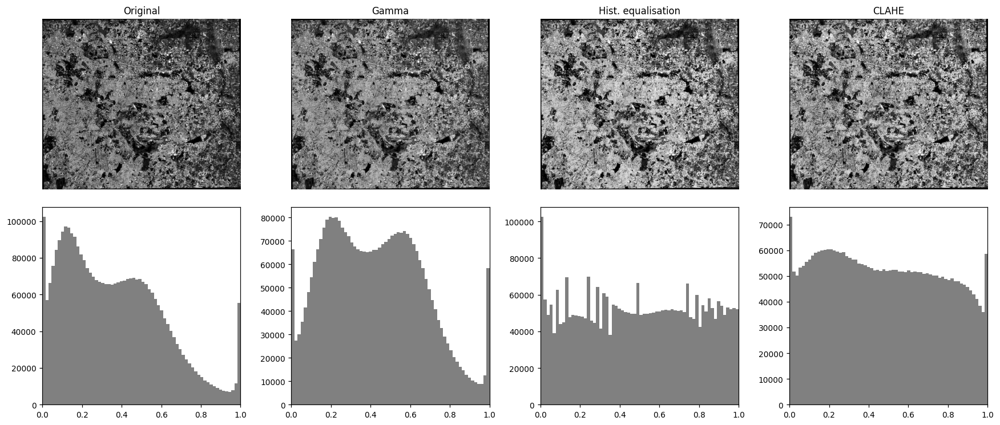

In [ ]:
gray = (0.299*rgb[..., 0] + 0.587*rgb[..., 1] + 0.114*rgb[..., 2]).astype(np.float32)
valid_in = ndi.binary_erosion(valid, iterations=2)          # excludes edge artefacts at the data border

def gamma_correct(x, g): return np.clip(x, 0, 1)**g
def hist_equalize(x, mask):
    u = np.uint8(np.clip(x, 0, 1)*255); h = np.bincount(u[mask], minlength=256).astype(float)
    cdf = np.cumsum(h); cdf = (cdf - cdf[cdf > 0].min())/max(cdf[-1] - cdf[cdf > 0].min(), 1)
    out = np.clip(cdf, 0, 1)[u].astype(np.float32); out[~mask] = 0; return out
def clahe(x, mask, clip, tile):
    u = np.uint8(np.clip(x, 0, 1)*255); u = u.copy(); u[~mask] = np.uint8(np.median(u[mask]))
    out = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(u).astype(np.float32)/255
    out[~mask] = 0; return out
def entropy(x, mask):
    h = np.bincount(np.uint8(np.clip(x, 0, 1)*255)[mask], minlength=256).astype(float); p = h[h > 0]/h.sum()
    return float(-(p*np.log2(p)).sum())

enh = {"Original": gray, "Gamma": gamma_correct(gray, CFG["gamma"]),
       "Hist. equalisation": hist_equalize(gray, valid),
       "CLAHE": clahe(gray, valid, CFG["clahe_clip"], CFG["clahe_tile"])}
enh_rows = []
for k, v in enh.items():
    x = v[valid]
    enh_rows.append({"method": k, "entropy_bits": entropy(v, valid), "rms_contrast_std": float(x.std()),
                     "dynamic_range_p98_p2": float(np.percentile(x, 98) - np.percentile(x, 2)), "mean": float(x.mean())})
enh_df = pd.DataFrame(enh_rows).round(4); display(enh_df); enh_df.to_csv(TAB/"enhancement_metrics.csv", index=False)
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for j, (k, v) in enumerate(enh.items()):
    axs[0, j].imshow(v, cmap="gray", vmin=0, vmax=1); axs[0, j].set_title(k); axs[0, j].axis("off")
    axs[1, j].hist(v[valid], bins=64, color="gray"); axs[1, j].set_xlim(0, 1)
plt.tight_layout(); savefig("enhancement_comparison.png"); plt.show()

saved GeoVision_DIP_Output/figures/spatial_filters.png


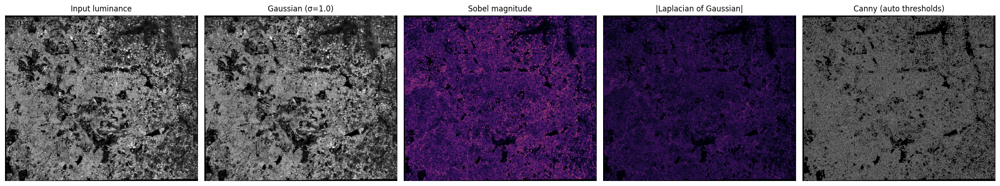

,input,canny_edge_density_%
0,original luminance,28.045
1,CLAHE-enhanced luminance,28.802


In [ ]:
def auto_canny(u8, mask):
    hi, _ = cv2.threshold(u8[mask].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    hi = float(max(hi, 20)); return cv2.Canny(u8, 0.5*hi, hi) > 0

def filters(img, mask, sigma):
    g = cv2.GaussianBlur(np.ascontiguousarray(img, np.float32), (0, 0), sigma)
    sx, sy = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    mag, ang = cv2.magnitude(sx, sy), np.degrees(np.arctan2(sy, sx))
    log = cv2.Laplacian(g, cv2.CV_32F, ksize=3)
    e = auto_canny(np.uint8(np.clip(g, 0, 1)*255), mask) & valid_in
    return g, mag, ang, log, e

gray_fill = gray.copy(); gray_fill[~valid] = np.median(gray[valid])      # avoid artificial border edges
g, sob, ang, lap, edges = filters(gray_fill, valid, CFG["gauss_sigma"])
n01 = lambda x: np.abs(x)/max(np.abs(x[valid_in]).max(), 1e-9)
fig, axs = plt.subplots(1, 5, figsize=(20, 4.3))
for a, (im, t, cm) in zip(axs, [(gray, "Input luminance", "gray"), (g, f"Gaussian (σ={CFG['gauss_sigma']})", "gray"),
                                (n01(sob), "Sobel magnitude", "magma"), (n01(lap), "|Laplacian of Gaussian|", "magma"),
                                (edges, "Canny (auto thresholds)", "gray")]):
    a.imshow(np.where(valid, im, 0), cmap=cm); a.set_title(t); a.axis("off")
plt.tight_layout(); savefig("spatial_filters.png"); plt.show()

edges_clahe = auto_canny(np.uint8(np.clip(cv2.GaussianBlur(enh["CLAHE"], (0, 0), CFG["gauss_sigma"]), 0, 1)*255), valid) & valid_in
edge_df = pd.DataFrame([{"input": "original luminance", "canny_edge_density_%": 100*edges[valid_in].mean()},
                        {"input": "CLAHE-enhanced luminance", "canny_edge_density_%": 100*edges_clahe[valid_in].mean()}]).round(3)
display(edge_df); edge_df.to_csv(TAB/"edge_density_original_vs_clahe.csv", index=False)

saved GeoVision_DIP_Output/figures/indices_and_spatial_features.png


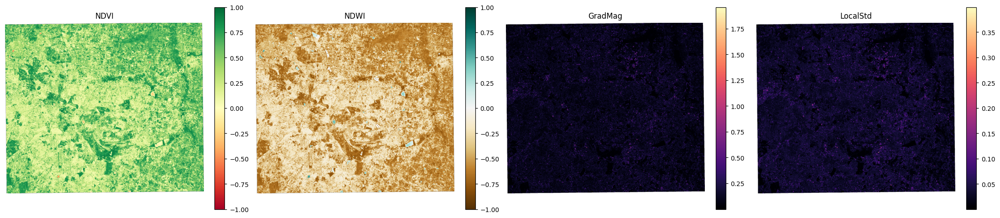

NDVI valid range: -0.6154428124427795 0.9477106332778931 | NDWI: -0.8552435636520386 0.6902095675468445


In [ ]:
def build_features(st, cfg=CFG):
    # Return dict name -> 2-D float32 array; identical code is used for training and offline inference.
    r, v, B_ = st["raster"], st["valid"], st["B"]
    F = {}
    if st["spectral"]:
        for nm, k in zip(["Blue", "Green", "Red", "NIR"], ["blue", "green", "red", "nir"]): F[nm] = r[st["bidx"][k]]
        raw = list(F)
        F["NDVI"] = np.clip((F["NIR"] - F["Red"])/(F["NIR"] + F["Red"] + EPS), -1, 1).astype(np.float32)
        F["NDWI"] = np.clip((F["Green"] - F["NIR"])/(F["Green"] + F["NIR"] + EPS), -1, 1).astype(np.float32)
        lum = (F["Blue"] + F["Green"] + F["Red"])/3
    else:
        for i in range(B_): F[f"Ch{i+1}"] = r[i]
        raw = list(F); lum = r.mean(0)
    lum = lum.astype(np.float32).copy(); lum[~v] = np.median(lum[v])
    sm = cv2.GaussianBlur(lum, (0, 0), cfg["gauss_sigma"])
    F["GradMag"] = cv2.magnitude(cv2.Sobel(sm, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(sm, cv2.CV_32F, 0, 1, ksize=3))
    w = cfg["texture_window"]; m1 = ndi.uniform_filter(lum, w); m2 = ndi.uniform_filter(lum*lum, w)
    F["LocalStd"] = np.sqrt(np.maximum(m2 - m1*m1, 0)).astype(np.float32)
    return F, raw

F, RAW = build_features(S)
if spectral:
    fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
    for a, (k, cm, vr) in zip(axs, [("NDVI", "RdYlGn", (-1, 1)), ("NDWI", "BrBG", (-1, 1)), ("GradMag", "magma", None), ("LocalStd", "magma", None)]):
        d = np.ma.masked_where(~valid, F[k]); im = a.imshow(d, cmap=cm, vmin=None if vr is None else vr[0], vmax=None if vr is None else vr[1])
        a.set_title(k); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046)
    plt.tight_layout(); savefig("indices_and_spatial_features.png"); plt.show()
    print("NDVI valid range:", float(F["NDVI"][valid].min()), float(F["NDVI"][valid].max()),
          "| NDWI:", float(F["NDWI"][valid].min()), float(F["NDWI"][valid].max()))
else:
    print("Spectral indices skipped (input not verified as multispectral). Feature sets: raw channels and raw + spatial.")

A_raw | inertia (scaled space): 63065.6 | cluster sizes: [66661 52643  5169 32183]
B_raw_indices | inertia (scaled space): 93876.5 | cluster sizes: [52196 41600  5132 57728]
C_raw_indices_spatial | inertia (scaled space): 173619.9 | cluster sizes: [69677 76585  5320  5074]
saved GeoVision_DIP_Output/figures/cluster_maps_all_feature_sets.png


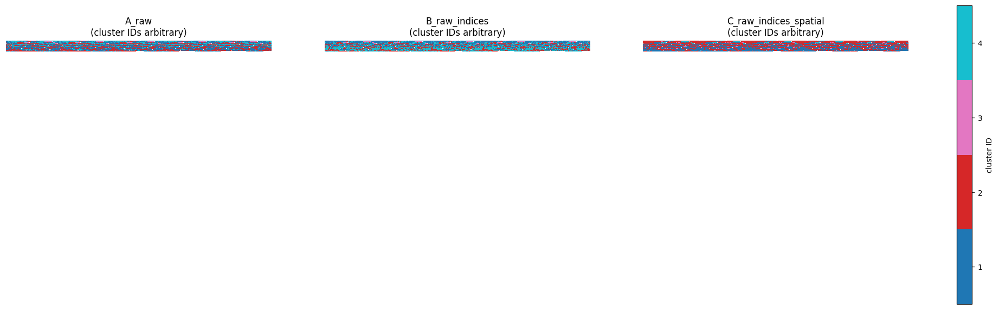

In [ ]:
BATCH = 100000
def fit_model(X, k, seed, n_init=10):
    r = np.random.default_rng(seed); m = min(CFG["max_train"], len(X)); ix = r.choice(len(X), m, replace=False)
    sc = StandardScaler().fit(X[ix])
    km = MiniBatchKMeans(n_clusters=k, random_state=seed, batch_size=4096, n_init=n_init, max_iter=200).fit(sc.transform(X[ix]))
    return sc, km
def predict(sc, km, X):
    out = np.empty(len(X), np.int32)
    for s in range(0, len(X), BATCH): out[s:s+BATCH] = km.predict(sc.transform(X[s:s+BATCH]))
    return out

exp = {}
for key, X in Xs.items():
    sc, km = fit_model(X, K, SEED)
    lab = predict(sc, km, X)
    lm = np.zeros(H*W, np.uint8); lm[vidx] = lab + 1                      # 0 = NoData, 1..K = cluster IDs
    exp[key] = dict(scaler=sc, model=km, flat=lab, map=lm.reshape(H, W), features=FEATURE_SETS[key])
    print(key, "| inertia (scaled space):", round(float(km.inertia_), 1), "| cluster sizes:", np.bincount(lab, minlength=K))

cmap = plt.get_cmap("tab10", K)
fig, axs = plt.subplots(1, len(exp), figsize=(7*len(exp), 6.5), squeeze=False)
for a, (key, e) in zip(axs[0], exp.items()):
    im = a.imshow(np.ma.masked_where(e["map"] == 0, e["map"]), cmap=cmap, vmin=0.5, vmax=K+0.5, interpolation="nearest")
    a.set_title(f"{key}\n(cluster IDs arbitrary)"); a.axis("off")
plt.colorbar(im, ax=axs[0].tolist(), ticks=range(1, K+1), fraction=0.02, label="cluster ID")
savefig("cluster_maps_all_feature_sets.png"); plt.show()

Otsu NDWI threshold = -0.420 | candidate pixels = 1,571,936 (1003.43% of valid)


,feature_set,highest_NDWI_cluster,mean_NDWI_of_that_cluster,IoU_with_NDWI_mask
0,A_raw,2,-0.5399,0.0046
1,B_raw_indices,2,-0.5388,0.0038
2,C_raw_indices_spatial,1,-0.5395,0.0061


saved GeoVision_DIP_Output/figures/ndwi_mask_morphology.png


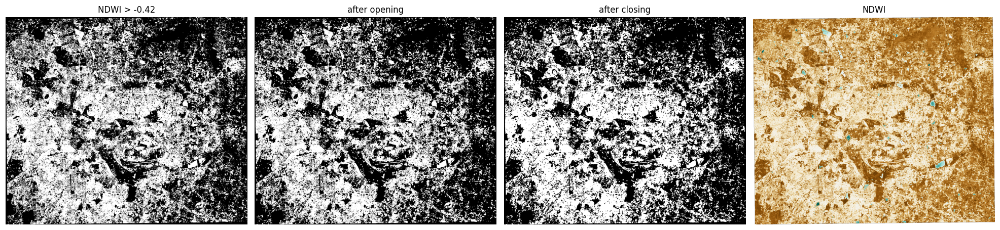

In [ ]:
water_df = pd.DataFrame()
if spectral:
    nd = F["NDWI"]; u = np.uint8(np.clip((nd[valid] + 1)/2, 0, 1)*255).reshape(-1, 1)
    thr_u, _ = cv2.threshold(u, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU); thr = float(thr_u)/255*2 - 1
    cand = ((nd > thr) & valid).astype(np.uint8); ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    opened = cv2.morphologyEx(cand, cv2.MORPH_OPEN, ker); closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, ker).astype(bool)
    print(f"Otsu NDWI threshold = {thr:.3f} | candidate pixels = {closed.sum():,} ({100*closed.sum()/NV:.2f}% of valid)")
    rows = []
    for key, e in exp.items():
        means = [float(nd[(e['map'] == c) & valid].mean()) if ((e['map'] == c) & valid).any() else -9 for c in range(1, K+1)]
        c = int(np.argmax(means)) + 1; m = (e["map"] == c); iou = float((m & closed).sum()/max((m | closed).sum(), 1))
        rows.append({"feature_set": key, "highest_NDWI_cluster": c, "mean_NDWI_of_that_cluster": means[c-1], "IoU_with_NDWI_mask": iou})
    water_df = pd.DataFrame(rows); display(water_df.round(4)); water_df.to_csv(TAB/"ndwi_mask_consistency.csv", index=False)
    fig, axs = plt.subplots(1, 4, figsize=(18, 4.3))
    for a, (im, t) in zip(axs, [(cand, f"NDWI > {thr:.2f}"), (opened, "after opening"), (closed, "after closing"), (np.ma.masked_where(~valid, nd), "NDWI")]):
        a.imshow(im, cmap="gray" if t != "NDWI" else "BrBG"); a.set_title(t); a.axis("off")
    plt.tight_layout(); savefig("ndwi_mask_morphology.png"); plt.show()
else:
    print("Skipped: no verified NIR/Green bands.")

## Limitations
1. Single scene, single date (26 Dec 2021), one study area; no temporal or cross-region claim.
2. Unsupervised clusters are not validated classes; no independent reference labels → no accuracy, precision or recall.
3. Silhouette/DB/CH are internal measures; own-space values are not comparable across feature sets, and common-space values favour set A by construction.
4. NDWI mask and cluster consistency use the same bands (circular as validation).
5. Input rasters were resampled to a ~9.2 m grid by the download service, so results are not at native 10 m Sentinel-2 geometry. Areas use the working-resolution pixel area.
6. Results depend on K, scene, season, atmospheric correction and preprocessing; resizing (if triggered) changes spatial scale.
7. Colab is not air-gapped; offline operation requires a local run with pre-installed packages and the saved bundle.

## Interpretation

* If C's *common-space* silhouette is lower than A's, spatial features pulled clusters away from pure spectral separation; if its fragmentation is lower, they trade spectral purity for spatial coherence.
* If majority-filtering changes set A's fragmentation more than set C's, spatial features already supply part of the smoothing.
* Set C adds gradient and texture features, which can make clusters reflect edge/texture zones rather than surface material; check its cluster summaries before reading it as "better".
* A Canny enrichment above 1 means boundaries coincide with edges more than chance; it does not mean the boundaries are "correct".
* Low stability (ARI far below 1) means the partition depends on the random sample/initialisation.
